In [1]:
# Uncomment and run only if packages are not already installed

# !pip install numpy pandas matplotlib scipy scikit-learn

# !pip install rasterio geopandas shapely rasterstats

# !pip install rioxarray xarray

# !pip install pyproj fiona

# !pip install tqdm

# !pip install jupyterlab ipykernel

In [2]:
# ============================================================
# Multi-temporal Drought Assessment using MODIS NDVI
# Cell 1 : Import Required Libraries
# Author : Anshuman Tripathi
# ============================================================

# ------------------------------
# Standard Libraries
# ------------------------------
import os
import glob
from pathlib import Path

# ------------------------------
# Numerical Computing
# ------------------------------
import numpy as np
import pandas as pd

# ------------------------------
# Geospatial Libraries
# ------------------------------
import rasterio
from rasterio.plot import show
from rasterio.mask import mask
from rasterio.features import shapes

import geopandas as gpd

from shapely.geometry import shape

import rioxarray as rxr
import xarray as xr

# ------------------------------
# Statistics
# ------------------------------
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression

# ------------------------------
# Visualization
# ------------------------------
import matplotlib.pyplot as plt

# ------------------------------
# Progress Bar
# ------------------------------
from tqdm import tqdm

# ============================================================
# Display Versions
# ============================================================

print("=" * 60)
print("Multi-temporal Drought Assessment Project")
print("=" * 60)

print(f"NumPy       : {np.__version__}")
print(f"Pandas      : {pd.__version__}")
print(f"GeoPandas   : {gpd.__version__}")
print(f"Rasterio    : {rasterio.__version__}")
print(f"Matplotlib  : {plt.matplotlib.__version__}")

print("=" * 60)
print("Libraries Imported Successfully")
print("=" * 60)

Multi-temporal Drought Assessment Project
NumPy       : 2.5.1
Pandas      : 3.0.5
GeoPandas   : 1.1.4
Rasterio    : 1.5.0
Matplotlib  : 3.11.1
Libraries Imported Successfully


In [3]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 1 : Install Dependencies (Run Only Once)
# Author : Anshuman Tripathi
# ===============================================================

# Uncomment the following line if the packages are not installed.

# !pip install numpy pandas matplotlib scipy scikit-learn rasterio geopandas shapely rasterstats rioxarray xarray pyproj fiona tqdm jupyterlab ipykernel

In [4]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 1 : Import Required Libraries
# Author : Anshuman Tripathi
# ===============================================================

# ---------------------------------------------------------------
# Standard Libraries
# ---------------------------------------------------------------
import os
import glob
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------
# Numerical & Data Analysis
# ---------------------------------------------------------------
import numpy as np
import pandas as pd

# ---------------------------------------------------------------
# Geospatial Libraries
# ---------------------------------------------------------------
import rasterio
from rasterio.plot import show
from rasterio.mask import mask
from rasterio.features import shapes
from rasterio.transform import Affine

import geopandas as gpd
from shapely.geometry import shape

import rioxarray as rxr
import xarray as xr

# ---------------------------------------------------------------
# Statistics & Machine Learning
# ---------------------------------------------------------------
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression

# ---------------------------------------------------------------
# Visualization
# ---------------------------------------------------------------
import matplotlib.pyplot as plt

# Default figure settings
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

# ---------------------------------------------------------------
# Progress Bar
# ---------------------------------------------------------------
from tqdm import tqdm

# ===============================================================
# Display Environment Information
# ===============================================================

print("=" * 65)
print(" Multi-temporal Drought Assessment using MODIS NDVI & VCI")
print("=" * 65)

print(f"NumPy        : {np.__version__}")
print(f"Pandas       : {pd.__version__}")
print(f"GeoPandas    : {gpd.__version__}")
print(f"Rasterio     : {rasterio.__version__}")
print(f"Matplotlib   : {plt.matplotlib.__version__}")

print("=" * 65)
print(" All required libraries imported successfully.")
print("=" * 65)

 Multi-temporal Drought Assessment using MODIS NDVI & VCI
NumPy        : 2.5.1
Pandas       : 3.0.5
GeoPandas    : 1.1.4
Rasterio     : 1.5.0
Matplotlib   : 3.11.1
 All required libraries imported successfully.


In [5]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 2 : Project Paths & Load Input Data
# Author : Anshuman Tripathi
# ===============================================================

# ---------------------------------------------------------------
# Project Root Directory
# ---------------------------------------------------------------

PROJECT_DIR = Path(
    "/home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main"
)

# ---------------------------------------------------------------
# Input Directories
# ---------------------------------------------------------------

DATA_DIR = PROJECT_DIR / "data"

NDVI_DIR = DATA_DIR / "NVDI"

AOI_DIR = DATA_DIR / "bundelkhand shape file"

NDVI_STATS_CSV = DATA_DIR / "Bundelkhand_Annual_NDVI_Statistics.csv"

# ---------------------------------------------------------------
# Output Directories
# ---------------------------------------------------------------

OUTPUT_DIR = PROJECT_DIR / "results"

MAP_DIR = OUTPUT_DIR / "Maps"

GRAPH_DIR = OUTPUT_DIR / "Graphs"

TABLE_DIR = OUTPUT_DIR / "Tables"

RASTER_DIR = OUTPUT_DIR / "Raster"

VECTOR_DIR = OUTPUT_DIR / "Vector"

# ---------------------------------------------------------------
# Create Output Folders (if not already present)
# ---------------------------------------------------------------

for folder in [
    OUTPUT_DIR,
    MAP_DIR,
    GRAPH_DIR,
    TABLE_DIR,
    RASTER_DIR,
    VECTOR_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------
# Automatically Load NDVI GeoTIFF Files
# ---------------------------------------------------------------

ndvi_files = sorted(NDVI_DIR.glob("NDVI_*.tif"))

# ---------------------------------------------------------------
# Locate AOI Shapefile
# ---------------------------------------------------------------

shp_files = list(AOI_DIR.glob("*.shp"))

if len(shp_files) == 0:
    raise FileNotFoundError("No Shapefile (.shp) found in AOI directory.")

AOI_SHP = shp_files[0]

# ---------------------------------------------------------------
# Read AOI
# ---------------------------------------------------------------

aoi = gpd.read_file(AOI_SHP)

# ---------------------------------------------------------------
# Read Annual NDVI Statistics CSV
# ---------------------------------------------------------------

ndvi_stats = pd.read_csv(NDVI_STATS_CSV)

# ---------------------------------------------------------------
# Display Project Information
# ---------------------------------------------------------------

print("=" * 70)
print("PROJECT DIRECTORY")
print(PROJECT_DIR)

print("\nDATA DIRECTORY")
print(DATA_DIR)

print("\nAOI SHAPEFILE")
print(AOI_SHP.name)

print("\nNDVI CSV")
print(NDVI_STATS_CSV.name)

print("\nTOTAL NDVI FILES FOUND :", len(ndvi_files))

print("\nNDVI FILES")

for file in ndvi_files:
    print("  •", file.name)

print("=" * 70)

# ---------------------------------------------------------------
# Display AOI Information
# ---------------------------------------------------------------

print("\nAOI INFORMATION")
print(aoi.info())

# ---------------------------------------------------------------
# Display NDVI Statistics Preview
# ---------------------------------------------------------------

print("\nAnnual NDVI Statistics")

display(ndvi_stats.head())

PROJECT DIRECTORY
/home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main

DATA DIRECTORY
/home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/data

AOI SHAPEFILE
Bundelkhand_AOI_Districts.shp

NDVI CSV
Bundelkhand_Annual_NDVI_Statistics.csv

TOTAL NDVI FILES FOUND : 9

NDVI FILES
  • NDVI_2015.tif
  • NDVI_2016.tif
  • NDVI_2017.tif
  • NDVI_2018.tif
  • NDVI_2019.tif
  • NDVI_2020.tif
  • NDVI_2021.tif
  • NDVI_2022.tif
  • NDVI_2023.tif

AOI INFORMATION
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Shape_Leng  13 non-null     float64 
 1   STATUS      13 non-null     str     
 2   ADM1_CODE   13 non-null     int32   
 3   ADM0_NAME   13 non-null     str     
 4   STR2_YEAR   13 non-null     int32   
 5   ADM2_NAME   13 non-null     str     

,system:index,Image_Count,Max_NDVI,Mean_NDVI,Min_NDVI,StdDev_NDVI,Year,.geo
0,0,23,0.7788,0.369606,-0.17845,0.076673,2015.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
1,1,23,0.7220,0.346001,-0.19720,0.069330,2016.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
2,2,23,0.7542,0.392357,-0.19540,0.080017,2017.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
3,3,23,0.7087,0.348744,-0.19340,0.068673,2018.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
4,4,23,0.7319,0.373404,-0.19710,0.067078,2019.0,"{""type"":""MultiPoint"",""coordinates"":[]}"


In [8]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Save Utilities (Run Once)
# Author : Anshuman Tripathi
# ===============================================================

import os
import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt

# ===============================================================
# Create Output Directories
# ===============================================================

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MAP_DIR.mkdir(parents=True, exist_ok=True)
GRAPH_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
RASTER_DIR.mkdir(parents=True, exist_ok=True)
VECTOR_DIR.mkdir(parents=True, exist_ok=True)

# ===============================================================
# Save Matplotlib Figure
# ===============================================================

def save_figure(filename,
                folder=GRAPH_DIR,
                dpi=300,
                transparent=False):

    filepath = folder / filename

    plt.savefig(
        filepath,
        dpi=dpi,
        bbox_inches="tight",
        transparent=transparent
    )

    print(f"Figure Saved : {filepath}")

# ===============================================================
# Save Raster (GeoTIFF)
# ===============================================================

def save_raster(array,
                metadata,
                filename,
                folder=RASTER_DIR):

    filepath = folder / filename

    meta = metadata.copy()

    meta.update(
        dtype="float32",
        count=1,
        compress="lzw"
    )

    with rasterio.open(filepath, "w", **meta) as dst:
        dst.write(array.astype(np.float32), 1)

    print(f"Raster Saved : {filepath}")

# ===============================================================
# Save Integer Raster
# (Useful for Drought Classification)
# ===============================================================

def save_classified_raster(array,
                           metadata,
                           filename,
                           folder=RASTER_DIR):

    filepath = folder / filename

    meta = metadata.copy()

    meta.update(
        dtype="uint8",
        count=1,
        compress="lzw"
    )

    with rasterio.open(filepath, "w", **meta) as dst:
        dst.write(array.astype(np.uint8), 1)

    print(f"Classified Raster Saved : {filepath}")

# ===============================================================
# Save CSV
# ===============================================================

def save_csv(df,
             filename,
             folder=TABLE_DIR):

    filepath = folder / filename

    df.to_csv(filepath, index=False)

    print(f"CSV Saved : {filepath}")

# ===============================================================
# Save GeoDataFrame
# ===============================================================

def save_vector(gdf,
                filename,
                folder=VECTOR_DIR):

    filepath = folder / filename

    gdf.to_file(filepath)

    print(f"Vector Saved : {filepath}")

# ===============================================================
# Save NumPy Array
# ===============================================================

def save_numpy(array,
               filename,
               folder=RASTER_DIR):

    filepath = folder / filename

    np.save(filepath, array)

    print(f"NumPy Array Saved : {filepath}")

# ===============================================================
# Display Output Folder Structure
# ===============================================================

print("=" * 70)
print("OUTPUT DIRECTORY")
print("=" * 70)

print(f"Maps      : {MAP_DIR}")
print(f"Graphs    : {GRAPH_DIR}")
print(f"Tables    : {TABLE_DIR}")
print(f"Raster    : {RASTER_DIR}")
print(f"Vector    : {VECTOR_DIR}")

print("=" * 70)
print("Save Utilities Loaded Successfully")
print("=" * 70)

OUTPUT DIRECTORY
Maps      : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps
Graphs    : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Graphs
Tables    : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Tables
Raster    : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster
Vector    : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Vector
Save Utilities Loaded Successfully


In [9]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 3 : Raster Data Validation (QA/QC)
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 80)
print("VALIDATING NDVI RASTER DATA")
print("=" * 80)

# ---------------------------------------------------------------
# Create Empty List for Raster Metadata
# ---------------------------------------------------------------

raster_info = []

# ---------------------------------------------------------------
# Read Every NDVI Raster
# ---------------------------------------------------------------

for raster_path in ndvi_files:

    with rasterio.open(raster_path) as src:

        raster_info.append({

            "Year": raster_path.stem.split("_")[1],

            "Filename": raster_path.name,

            "Width": src.width,

            "Height": src.height,

            "Bands": src.count,

            "CRS": str(src.crs),

            "Resolution_X": src.res[0],

            "Resolution_Y": src.res[1],

            "DataType": src.dtypes[0],

            "NoData": src.nodata,

            "Bounds": src.bounds

        })

# ---------------------------------------------------------------
# Convert Metadata to DataFrame
# ---------------------------------------------------------------

validation_df = pd.DataFrame(raster_info)

# ---------------------------------------------------------------
# Display Validation Table
# ---------------------------------------------------------------

display(validation_df)

# ---------------------------------------------------------------
# Check CRS Consistency
# ---------------------------------------------------------------

crs_check = validation_df["CRS"].nunique()

# ---------------------------------------------------------------
# Check Raster Dimensions
# ---------------------------------------------------------------

dimension_check = (
    validation_df["Width"].nunique() == 1 and
    validation_df["Height"].nunique() == 1
)

# ---------------------------------------------------------------
# Check Pixel Resolution
# ---------------------------------------------------------------

resolution_check = (
    validation_df["Resolution_X"].nunique() == 1 and
    validation_df["Resolution_Y"].nunique() == 1
)

# ---------------------------------------------------------------
# Check Number of Bands
# ---------------------------------------------------------------

band_check = validation_df["Bands"].nunique() == 1

# ---------------------------------------------------------------
# Print Validation Summary
# ---------------------------------------------------------------

print("\n" + "=" * 80)
print("QUALITY ASSESSMENT REPORT")
print("=" * 80)

print(f"Total NDVI Files       : {len(validation_df)}")

print(f"Same CRS               : {'YES' if crs_check == 1 else 'NO'}")

print(f"Same Dimensions        : {'YES' if dimension_check else 'NO'}")

print(f"Same Resolution        : {'YES' if resolution_check else 'NO'}")

print(f"Same Band Count        : {'YES' if band_check else 'NO'}")

print("=" * 80)

# ---------------------------------------------------------------
# Display Raster Properties
# ---------------------------------------------------------------

sample = validation_df.iloc[0]

print("\nSample Raster Properties")

print(f"CRS                  : {sample['CRS']}")
print(f"Raster Size          : {sample['Width']} × {sample['Height']}")
print(f"Pixel Size           : {sample['Resolution_X']} × {sample['Resolution_Y']}")
print(f"Band Count           : {sample['Bands']}")
print(f"Data Type            : {sample['DataType']}")
print(f"NoData Value         : {sample['NoData']}")

print("=" * 80)

# ---------------------------------------------------------------
# Stop Execution if Validation Fails
# ---------------------------------------------------------------

assert crs_check == 1, "ERROR: CRS mismatch detected."

assert dimension_check, "ERROR: Raster dimensions are different."

assert resolution_check, "ERROR: Raster resolution mismatch."

assert band_check, "ERROR: Number of raster bands mismatch."

print("\nAll NDVI rasters passed QA/QC validation successfully.")

# ===============================================================
# Save Raster Validation Report
# ===============================================================

save_csv(
    validation_df,
    "NDVI_Raster_Validation_Report.csv"
)

print("\nValidation report saved successfully.")

VALIDATING NDVI RASTER DATA


,Year,Filename,Width,Height,Bands,CRS,Resolution_X,Resolution_Y,DataType,NoData,Bounds
0,2015,NDVI_2015.tif,1561,1469,1,EPSG:4326,0.002246,0.002246,float64,None,"(78.05236924893492, 23.14958487176007, 81.5580..."
1,2016,NDVI_2016.tif,1561,1469,1,EPSG:4326,0.002246,0.002246,float64,None,"(78.05236924893492, 23.14958487176007, 81.5580..."
2,2017,NDVI_2017.tif,1561,1469,1,EPSG:4326,0.002246,0.002246,float64,None,"(78.05236924893492, 23.14958487176007, 81.5580..."
3,2018,NDVI_2018.tif,1561,1469,1,EPSG:4326,0.002246,0.002246,float64,None,"(78.05236924893492, 23.14958487176007, 81.5580..."
4,2019,NDVI_2019.tif,1561,1469,1,EPSG:4326,0.002246,0.002246,float64,None,"(78.05236924893492, 23.14958487176007, 81.5580..."
5,2020,NDVI_2020.tif,1561,1469,1,EPSG:4326,0.002246,0.002246,float64,None,"(78.05236924893492, 23.14958487176007, 81.5580..."
6,2021,NDVI_2021.tif,1561,1469,1,EPSG:4326,0.002246,0.002246,float64,None,"(78.05236924893492, 23.14958487176007, 81.5580..."
7,2022,NDVI_2022.tif,1561,1469,1,EPSG:4326,0.002246,0.002246,float64,None,"(78.05236924893492, 23.14958487176007, 81.5580..."
8,2023,NDVI_2023.tif,1561,1469,1,EPSG:4326,0.002246,0.002246,float64,None,"(78.05236924893492, 23.14958487176007, 81.5580..."



QUALITY ASSESSMENT REPORT
Total NDVI Files       : 9
Same CRS               : YES
Same Dimensions        : YES
Same Resolution        : YES
Same Band Count        : YES

Sample Raster Properties
CRS                  : EPSG:4326
Raster Size          : 1561 × 1469
Pixel Size           : 0.002245788210298804 × 0.002245788210298804
Band Count           : 1
Data Type            : float64
NoData Value         : None

All NDVI rasters passed QA/QC validation successfully.
CSV Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Tables/NDVI_Raster_Validation_Report.csv

Validation report saved successfully.


In [10]:
from matplotlib_scalebar.scalebar import ScaleBar

In [11]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 4A : Load, Stack and Prepare NDVI Data
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("LOADING MULTI-TEMPORAL MODIS NDVI DATA")
print("=" * 90)

# ---------------------------------------------------------------
# Initialize Containers
# ---------------------------------------------------------------

ndvi_stack = []
years = []

# ---------------------------------------------------------------
# Read Every Annual NDVI Raster
# ---------------------------------------------------------------

for raster_path in tqdm(ndvi_files,
                        desc="Loading Annual NDVI"):

    with rasterio.open(raster_path) as src:

        ndvi = src.read(1).astype(np.float32)

        # Replace NoData with NaN
        if src.nodata is not None:
            ndvi[ndvi == src.nodata] = np.nan

        ndvi_stack.append(ndvi)

        years.append(
            int(raster_path.stem.split("_")[1])
        )

# ---------------------------------------------------------------
# Convert List → 3D NumPy Array
# Shape = (Years, Rows, Columns)
# ---------------------------------------------------------------

ndvi_stack = np.stack(ndvi_stack, axis=0)

print("\nNDVI Stack Shape :", ndvi_stack.shape)

# ---------------------------------------------------------------
# Read Raster Metadata
# ---------------------------------------------------------------

with rasterio.open(ndvi_files[0]) as src:

    raster_meta = src.meta.copy()

    transform = src.transform

    bounds = src.bounds

    crs = src.crs

# ---------------------------------------------------------------
# Save NDVI Stack
# ---------------------------------------------------------------

save_numpy(
    ndvi_stack,
    "NDVI_Stack.npy"
)

# ---------------------------------------------------------------
# Basic Statistics
# ---------------------------------------------------------------

print("\n")
print("="*90)

print(f"Study Period          : {years[0]} - {years[-1]}")

print(f"Total Images          : {len(years)}")

print(f"Raster Dimension      : {ndvi_stack.shape[2]} × {ndvi_stack.shape[1]}")

print(f"Minimum NDVI          : {np.nanmin(ndvi_stack):.4f}")

print(f"Maximum NDVI          : {np.nanmax(ndvi_stack):.4f}")

print(f"Mean NDVI             : {np.nanmean(ndvi_stack):.4f}")

print(f"Standard Deviation    : {np.nanstd(ndvi_stack):.4f}")

print("="*90)

# ---------------------------------------------------------------
# Prepare First NDVI Image (2015)
# ---------------------------------------------------------------

first_ndvi = ndvi_stack[0]

# ---------------------------------------------------------------
# Professional NDVI Colour Map
# ---------------------------------------------------------------

from matplotlib.colors import LinearSegmentedColormap

ndvi_cmap = LinearSegmentedColormap.from_list(

    "NDVI",

    [

        "#8c510a",   # Bare soil

        "#d8b365",

        "#f6e8c3",

        "#c7eae5",

        "#5ab4ac",

        "#01665e"    # Dense Vegetation

    ]

)

print("\nNDVI Stack Ready.")

print("Proceeding to Publication Map...")

LOADING MULTI-TEMPORAL MODIS NDVI DATA


Loading Annual NDVI: 100%|████████████████████████| 9/9 [00:00<00:00, 13.22it/s]



NDVI Stack Shape : (9, 1469, 1561)
NumPy Array Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/NDVI_Stack.npy


Study Period          : 2015 - 2023
Total Images          : 9
Raster Dimension      : 1561 × 1469
Minimum NDVI          : -0.1988
Maximum NDVI          : 0.7951
Mean NDVI             : 0.3918
Standard Deviation    : 0.0836

NDVI Stack Ready.
Proceeding to Publication Map...


Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/NDVI_2015_Publication_Map.png


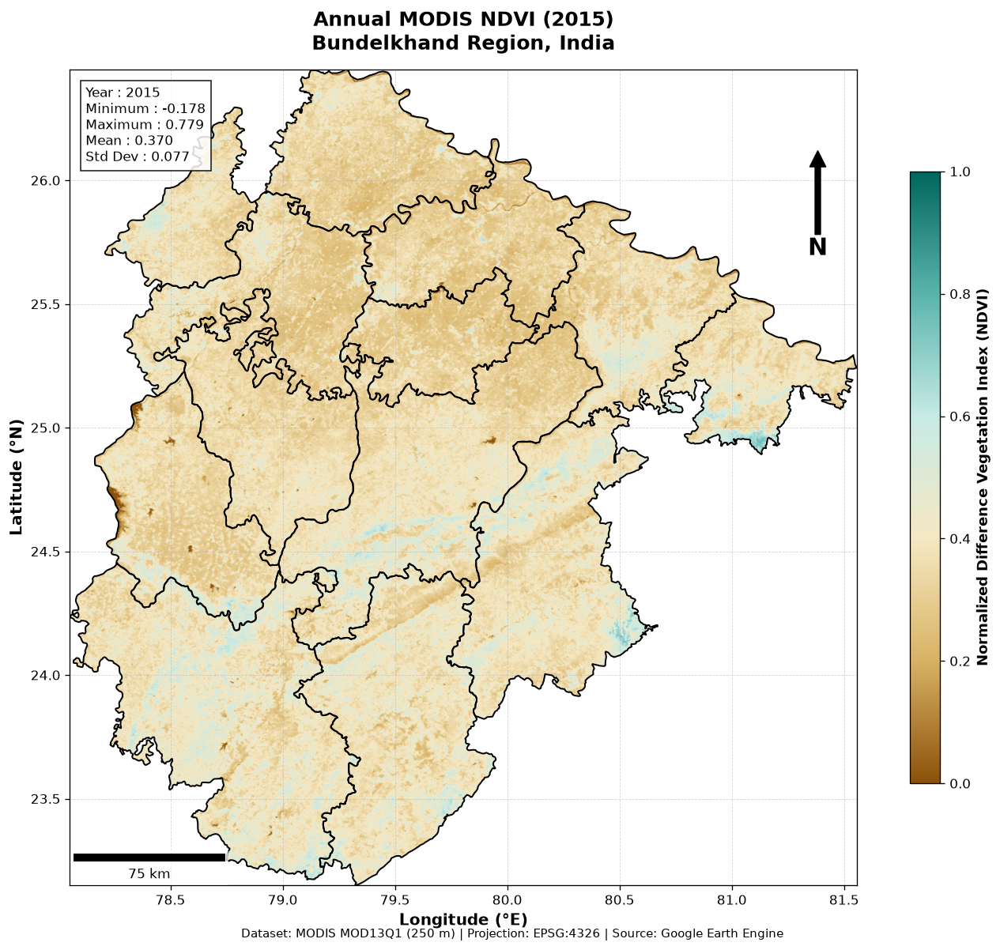

Publication-quality NDVI map generated successfully.
Saved to: /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/NDVI_2015_Publication_Map.png


In [21]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 4B : Publication Quality NDVI Map (2015)
# Author : Anshuman Tripathi
# ===============================================================

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib_scalebar.scalebar import ScaleBar

# ---------------------------------------------------------------
# Create Figure
# ---------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 10))

# ---------------------------------------------------------------
# Plot NDVI Raster
# ---------------------------------------------------------------

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

img = ax.imshow(
    first_ndvi,
    cmap=ndvi_cmap,
    extent=extent,
    origin="upper",
    vmin=0,
    vmax=1
)

# ---------------------------------------------------------------
# Overlay Bundelkhand Boundary
# ---------------------------------------------------------------

aoi.boundary.plot(
    ax=ax,
    edgecolor="black",
    linewidth=1.2
)

# ---------------------------------------------------------------
# Axis Labels
# ---------------------------------------------------------------

ax.set_xlabel(
    "Longitude (°E)",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Latitude (°N)",
    fontsize=12,
    fontweight="bold"
)

# ---------------------------------------------------------------
# Title
# ---------------------------------------------------------------

ax.set_title(
    "Annual MODIS NDVI (2015)\nBundelkhand Region, India",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# ---------------------------------------------------------------
# Grid
# ---------------------------------------------------------------

ax.grid(
    linestyle="--",
    linewidth=0.5,
    alpha=0.5
)

# ---------------------------------------------------------------
# Colorbar
# ---------------------------------------------------------------

cbar = fig.colorbar(
    img,
    ax=ax,
    shrink=0.75
)

cbar.set_label(
    "Normalized Difference Vegetation Index (NDVI)",
    fontsize=11,
    fontweight="bold"
)

# ---------------------------------------------------------------
# North Arrow
# ---------------------------------------------------------------

ax.annotate(
    "N",
    xy=(0.95, 0.90),
    xytext=(0.95, 0.78),
    arrowprops=dict(
        facecolor="black",
        width=4,
        headwidth=12
    ),
    ha="center",
    va="center",
    fontsize=18,
    fontweight="bold",
    xycoords=ax.transAxes
)

# ---------------------------------------------------------------
# Scale Bar
# ---------------------------------------------------------------
#
# NOTE:
# EPSG:4326 uses degrees, so this is only an approximate
# scale for visualization.
# A precise scale bar requires a projected CRS (e.g. UTM).
#

scalebar = ScaleBar(
    dx=111320,
    units="m",
    location="lower left",
    box_alpha=0.6,
    length_fraction=0.25
)

ax.add_artist(scalebar)

# ---------------------------------------------------------------
# Statistics Box
# ---------------------------------------------------------------

stats_text = (
    f"Year : {years[0]}\n"
    f"Minimum : {np.nanmin(first_ndvi):.3f}\n"
    f"Maximum : {np.nanmax(first_ndvi):.3f}\n"
    f"Mean : {np.nanmean(first_ndvi):.3f}\n"
    f"Std Dev : {np.nanstd(first_ndvi):.3f}"
)

ax.text(
    0.02,
    0.98,
    stats_text,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(
        facecolor="white",
        alpha=0.85,
        edgecolor="black"
    )
)

# ---------------------------------------------------------------
# Figure Information
# ---------------------------------------------------------------

plt.figtext(
    0.5,
    0.006,
    "Dataset: MODIS MOD13Q1 (250 m) | Projection: EPSG:4326 | Source: Google Earth Engine",
    ha="center",
    fontsize=9
)

plt.tight_layout()

# ---------------------------------------------------------------
# Save Publication Figure
# ---------------------------------------------------------------

save_figure(
    "NDVI_2015_Publication_Map.png",
    folder=MAP_DIR,
    dpi=300
)

# ---------------------------------------------------------------
# Display Figure
# ---------------------------------------------------------------

plt.show()

print("=" * 90)
print("Publication-quality NDVI map generated successfully.")
print("Saved to:", MAP_DIR / "NDVI_2015_Publication_Map.png")
print("=" * 90)

LOADING ANNUAL NDVI RASTERS


100%|█████████████████████████████████████████████| 9/9 [00:00<00:00, 13.22it/s]



Stack Created Successfully

Number of Years      : 9
Raster Height        : 1469
Raster Width         : 1561

Array Shape          : (9, 1469, 1561)
Data Type            : float32
Minimum NDVI Value   : -0.1988
Maximum NDVI Value   : 0.7951
Available Years
[2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/map.png


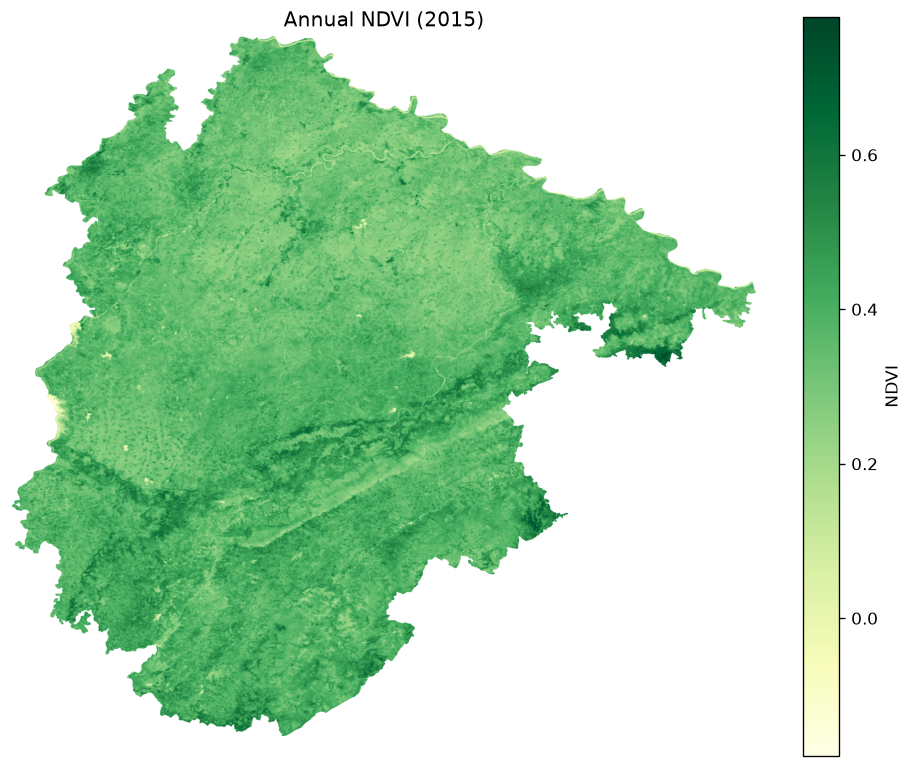

NDVI Stack Ready for Analysis


In [22]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 4 : Load & Stack Annual NDVI Rasters
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 80)
print("LOADING ANNUAL NDVI RASTERS")
print("=" * 80)

# ---------------------------------------------------------------
# Empty Lists
# ---------------------------------------------------------------

ndvi_stack = []
years = []

# ---------------------------------------------------------------
# Read Every NDVI GeoTIFF
# ---------------------------------------------------------------

for raster_path in tqdm(ndvi_files):

    with rasterio.open(raster_path) as src:

        # Read first band
        ndvi = src.read(1).astype(np.float32)

        # Replace NoData with NaN
        if src.nodata is not None:
            ndvi = np.where(ndvi == src.nodata, np.nan, ndvi)

        ndvi_stack.append(ndvi)

        year = int(raster_path.stem.split("_")[1])
        years.append(year)

# ---------------------------------------------------------------
# Convert List → NumPy Array
# Shape : (Years, Rows, Columns)
# ---------------------------------------------------------------

ndvi_stack = np.stack(ndvi_stack, axis=0)

# ---------------------------------------------------------------
# Save Raster Metadata
# (Used later while exporting rasters)
# ---------------------------------------------------------------

with rasterio.open(ndvi_files[0]) as src:

    raster_meta = src.meta.copy()

# ---------------------------------------------------------------
# Display Information
# ---------------------------------------------------------------

print("\nStack Created Successfully\n")

print(f"Number of Years      : {ndvi_stack.shape[0]}")
print(f"Raster Height        : {ndvi_stack.shape[1]}")
print(f"Raster Width         : {ndvi_stack.shape[2]}")

print(f"\nArray Shape          : {ndvi_stack.shape}")

print(f"Data Type            : {ndvi_stack.dtype}")

print(f"Minimum NDVI Value   : {np.nanmin(ndvi_stack):.4f}")

print(f"Maximum NDVI Value   : {np.nanmax(ndvi_stack):.4f}")

print("=" * 80)

# ---------------------------------------------------------------
# Display Available Years
# ---------------------------------------------------------------

print("Available Years")

print(years)

# ---------------------------------------------------------------
# Display First NDVI Image
# ---------------------------------------------------------------

plt.figure(figsize=(10,8))

plt.imshow(ndvi_stack[0], cmap="YlGn")

plt.colorbar(label="NDVI")

plt.title(f"Annual NDVI ({years[0]})")

plt.axis("off")

# ---------------------------------------------------------------
# Save Publication Figure
# ---------------------------------------------------------------

save_figure(
    "map.png",
    folder=MAP_DIR,
    dpi=300
)


plt.show()

print("=" * 80)
print("NDVI Stack Ready for Analysis")
print("=" * 80)

COMPUTING PIXEL-WISE MINIMUM NDVI (2015–2023)

Minimum NDVI Computation Completed Successfully.

NumPy Array Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/NDVI_Min.npy
Raster Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/NDVI_Min.tif
NDVI MINIMUM STATISTICS
Minimum NDVI     : -0.1988
Maximum NDVI     : 0.6901
Mean NDVI        : 0.3195
Std. Deviation   : 0.0643
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/NDVI_Min_Map.png


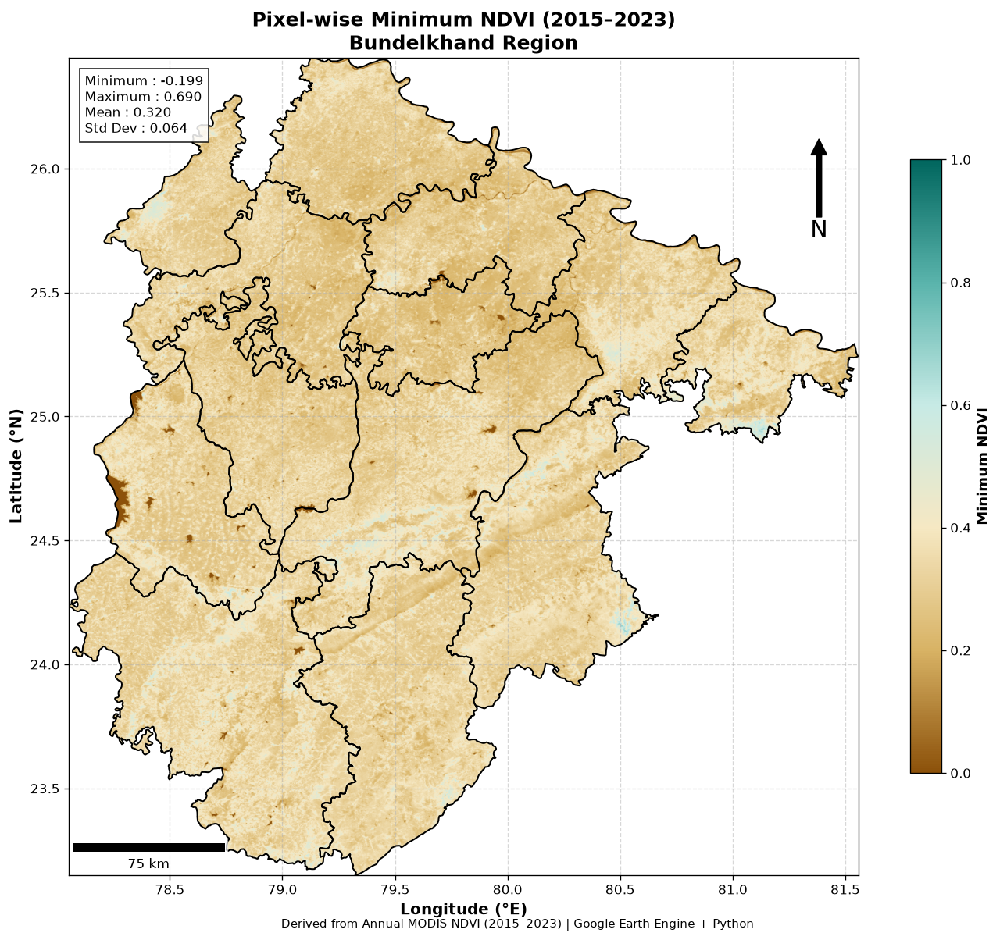

Minimum NDVI Raster Generated Successfully


In [24]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 5 : Compute Pixel-wise Minimum NDVI
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("COMPUTING PIXEL-WISE MINIMUM NDVI (2015–2023)")
print("=" * 90)

# ---------------------------------------------------------------
# Compute Minimum NDVI
# ---------------------------------------------------------------

ndvi_min = np.nanmin(ndvi_stack, axis=0)

print("\nMinimum NDVI Computation Completed Successfully.\n")

# ---------------------------------------------------------------
# Save NumPy Array
# ---------------------------------------------------------------

save_numpy(
    ndvi_min,
    "NDVI_Min.npy"
)

# ---------------------------------------------------------------
# Save GeoTIFF
# ---------------------------------------------------------------

save_raster(
    ndvi_min,
    raster_meta,
    "NDVI_Min.tif"
)

# ---------------------------------------------------------------
# Calculate Statistics
# ---------------------------------------------------------------

minimum = np.nanmin(ndvi_min)
maximum = np.nanmax(ndvi_min)
mean = np.nanmean(ndvi_min)
std = np.nanstd(ndvi_min)

print("=" * 90)
print("NDVI MINIMUM STATISTICS")
print("=" * 90)

print(f"Minimum NDVI     : {minimum:.4f}")
print(f"Maximum NDVI     : {maximum:.4f}")
print(f"Mean NDVI        : {mean:.4f}")
print(f"Std. Deviation   : {std:.4f}")

print("=" * 90)

# ---------------------------------------------------------------
# Create Publication Figure
# ---------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12,10))

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

image = ax.imshow(
    ndvi_min,
    cmap=ndvi_cmap,
    extent=extent,
    origin="upper",
    vmin=0,
    vmax=1
)

# AOI Boundary
aoi.boundary.plot(
    ax=ax,
    edgecolor="black",
    linewidth=1.2
)

# Labels
ax.set_xlabel(
    "Longitude (°E)",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Latitude (°N)",
    fontsize=12,
    fontweight="bold"
)

# Title
ax.set_title(
    "Pixel-wise Minimum NDVI (2015–2023)\nBundelkhand Region",
    fontsize=15,
    fontweight="bold"
)

# Grid
ax.grid(
    linestyle="--",
    alpha=0.5
)

# Colorbar
cbar = plt.colorbar(
    image,
    ax=ax,
    shrink=0.75
)

cbar.set_label(
    "Minimum NDVI",
    fontsize=11,
    fontweight="bold"
)

# North Arrow
ax.annotate(
    "N",
    xy=(0.95,0.90),
    xytext=(0.95,0.78),
    arrowprops=dict(
        facecolor="black",
        width=4,
        headwidth=12
    ),
    fontsize=18,
    ha="center",
    xycoords=ax.transAxes
)

# Scale Bar
scalebar = ScaleBar(
    dx=111320,
    units="m",
    location="lower left",
    length_fraction=0.25,
    box_alpha=0.7
)

ax.add_artist(scalebar)

# Statistics Box
stats = (
    f"Minimum : {minimum:.3f}\n"
    f"Maximum : {maximum:.3f}\n"
    f"Mean : {mean:.3f}\n"
    f"Std Dev : {std:.3f}"
)

ax.text(
    0.02,
    0.98,
    stats,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(
        facecolor="white",
        alpha=0.85
    )
)

# Footer
plt.figtext(
    0.5,
    0.005,
    "Derived from Annual MODIS NDVI (2015–2023) | Google Earth Engine + Python",
    ha="center",
    fontsize=9
)

plt.tight_layout()

# ---------------------------------------------------------------
# Save Publication Figure
# ---------------------------------------------------------------

save_figure(
    "NDVI_Min_Map.png",
    folder=MAP_DIR,
    dpi=300
)

plt.show()

print("=" * 90)
print("Minimum NDVI Raster Generated Successfully")
print("=" * 90)

COMPUTING PIXEL-WISE MAXIMUM NDVI (2015–2023)

Maximum NDVI Computation Completed Successfully.

NumPy Array Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/NDVI_Max.npy
Raster Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/NDVI_Max.tif
NDVI MAXIMUM STATISTICS
Minimum NDVI     : -0.1119
Maximum NDVI     : 0.7951
Mean NDVI        : 0.4740
Std. Deviation   : 0.0774
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/NDVI_Max_Map.png


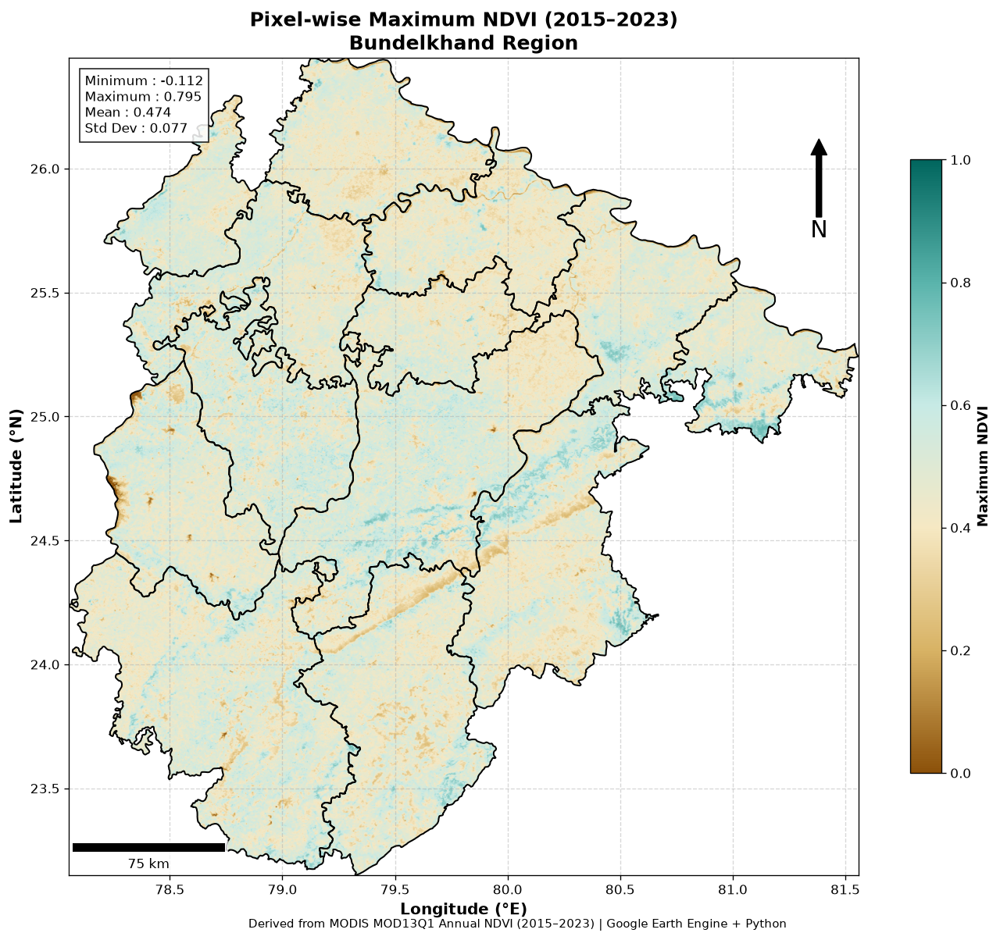

Maximum NDVI Raster Generated Successfully


In [25]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 6 : Compute Pixel-wise Maximum NDVI
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("COMPUTING PIXEL-WISE MAXIMUM NDVI (2015–2023)")
print("=" * 90)

# ---------------------------------------------------------------
# Compute Maximum NDVI
# ---------------------------------------------------------------

ndvi_max = np.nanmax(ndvi_stack, axis=0)

print("\nMaximum NDVI Computation Completed Successfully.\n")

# ---------------------------------------------------------------
# Save NumPy Array
# ---------------------------------------------------------------

save_numpy(
    ndvi_max,
    "NDVI_Max.npy"
)

# ---------------------------------------------------------------
# Save GeoTIFF
# ---------------------------------------------------------------

save_raster(
    ndvi_max,
    raster_meta,
    "NDVI_Max.tif"
)

# ---------------------------------------------------------------
# Calculate Statistics
# ---------------------------------------------------------------

minimum = np.nanmin(ndvi_max)
maximum = np.nanmax(ndvi_max)
mean = np.nanmean(ndvi_max)
std = np.nanstd(ndvi_max)

print("=" * 90)
print("NDVI MAXIMUM STATISTICS")
print("=" * 90)

print(f"Minimum NDVI     : {minimum:.4f}")
print(f"Maximum NDVI     : {maximum:.4f}")
print(f"Mean NDVI        : {mean:.4f}")
print(f"Std. Deviation   : {std:.4f}")

print("=" * 90)

# ---------------------------------------------------------------
# Create Publication Figure
# ---------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12,10))

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

image = ax.imshow(
    ndvi_max,
    cmap=ndvi_cmap,
    extent=extent,
    origin="upper",
    vmin=0,
    vmax=1
)

# ---------------------------------------------------------------
# AOI Boundary
# ---------------------------------------------------------------

aoi.boundary.plot(
    ax=ax,
    edgecolor="black",
    linewidth=1.2
)

# ---------------------------------------------------------------
# Axis Labels
# ---------------------------------------------------------------

ax.set_xlabel(
    "Longitude (°E)",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Latitude (°N)",
    fontsize=12,
    fontweight="bold"
)

# ---------------------------------------------------------------
# Title
# ---------------------------------------------------------------

ax.set_title(
    "Pixel-wise Maximum NDVI (2015–2023)\nBundelkhand Region",
    fontsize=15,
    fontweight="bold"
)

# ---------------------------------------------------------------
# Grid
# ---------------------------------------------------------------

ax.grid(
    linestyle="--",
    alpha=0.5
)

# ---------------------------------------------------------------
# Colorbar
# ---------------------------------------------------------------

cbar = plt.colorbar(
    image,
    ax=ax,
    shrink=0.75
)

cbar.set_label(
    "Maximum NDVI",
    fontsize=11,
    fontweight="bold"
)

# ---------------------------------------------------------------
# North Arrow
# ---------------------------------------------------------------

ax.annotate(
    "N",
    xy=(0.95,0.90),
    xytext=(0.95,0.78),
    arrowprops=dict(
        facecolor="black",
        width=4,
        headwidth=12
    ),
    fontsize=18,
    ha="center",
    xycoords=ax.transAxes
)

# ---------------------------------------------------------------
# Scale Bar
# ---------------------------------------------------------------

scalebar = ScaleBar(
    dx=111320,
    units="m",
    location="lower left",
    length_fraction=0.25,
    box_alpha=0.7
)

ax.add_artist(scalebar)

# ---------------------------------------------------------------
# Statistics Box
# ---------------------------------------------------------------

stats = (
    f"Minimum : {minimum:.3f}\n"
    f"Maximum : {maximum:.3f}\n"
    f"Mean : {mean:.3f}\n"
    f"Std Dev : {std:.3f}"
)

ax.text(
    0.02,
    0.98,
    stats,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(
        facecolor="white",
        edgecolor="black",
        alpha=0.85
    )
)

# ---------------------------------------------------------------
# Footer
# ---------------------------------------------------------------

plt.figtext(
    0.5,
    0.005,
    "Derived from MODIS MOD13Q1 Annual NDVI (2015–2023) | Google Earth Engine + Python",
    ha="center",
    fontsize=9
)

plt.tight_layout()

# ---------------------------------------------------------------
# Save Figure
# ---------------------------------------------------------------

save_figure(
    "NDVI_Max_Map.png",
    folder=MAP_DIR,
    dpi=300
)

# ---------------------------------------------------------------
# Display Figure
# ---------------------------------------------------------------

plt.show()

print("=" * 90)
print("Maximum NDVI Raster Generated Successfully")
print("=" * 90)

In [26]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 7A : Vegetation Condition Index (VCI) Calculation
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("CALCULATING VEGETATION CONDITION INDEX (VCI)")
print("=" * 90)

# ------------------------------------------------------------------
# VCI Formula
#
# VCI = ((NDVI - NDVImin) / (NDVImax - NDVImin)) × 100
#
# ------------------------------------------------------------------

# ---------------------------------------------------------------
# Prevent Division by Zero
# ---------------------------------------------------------------

denominator = ndvi_max - ndvi_min

denominator = np.where(
    denominator == 0,
    np.nan,
    denominator
)

# ---------------------------------------------------------------
# Empty Containers
# ---------------------------------------------------------------

vci_stack = []

vci_statistics = []

# ---------------------------------------------------------------
# Loop through every year
# ---------------------------------------------------------------

for i, year in enumerate(years):

    print(f"Processing VCI : {year}")

    ndvi = ndvi_stack[i]

    # -----------------------------------------------------------
    # Calculate VCI
    # -----------------------------------------------------------

    vci = ((ndvi - ndvi_min) / denominator) * 100

    # -----------------------------------------------------------
    # Limit Values
    # -----------------------------------------------------------

    vci = np.clip(vci, 0, 100)

    vci_stack.append(vci)

    # -----------------------------------------------------------
    # Statistics
    # -----------------------------------------------------------

    stats = {

        "Year": year,

        "Minimum_VCI": np.nanmin(vci),

        "Maximum_VCI": np.nanmax(vci),

        "Mean_VCI": np.nanmean(vci),

        "Median_VCI": np.nanmedian(vci),

        "Std_Deviation": np.nanstd(vci)

    }

    vci_statistics.append(stats)

# ---------------------------------------------------------------
# Convert List → NumPy Stack
# ---------------------------------------------------------------

vci_stack = np.stack(vci_stack)

# ---------------------------------------------------------------
# Statistics DataFrame
# ---------------------------------------------------------------

vci_statistics = pd.DataFrame(vci_statistics)

# ---------------------------------------------------------------
# Display Statistics
# ---------------------------------------------------------------

display(vci_statistics)

# ---------------------------------------------------------------
# Print Summary
# ---------------------------------------------------------------

print("\n")

print("=" * 90)

print("VCI CALCULATION COMPLETED")

print("=" * 90)

print(f"Years Processed        : {len(years)}")

print(f"VCI Stack Shape        : {vci_stack.shape}")

print(f"Minimum VCI            : {np.nanmin(vci_stack):.2f}")

print(f"Maximum VCI            : {np.nanmax(vci_stack):.2f}")

print(f"Mean VCI               : {np.nanmean(vci_stack):.2f}")

print("=" * 90)

# ---------------------------------------------------------------
# Save Complete Stack
# ---------------------------------------------------------------

save_numpy(

    vci_stack,

    "VCI_Stack.npy"

)

print("\nVCI Stack Saved Successfully.")

print("=" * 90)

CALCULATING VEGETATION CONDITION INDEX (VCI)
Processing VCI : 2015
Processing VCI : 2016
Processing VCI : 2017
Processing VCI : 2018
Processing VCI : 2019
Processing VCI : 2020
Processing VCI : 2021
Processing VCI : 2022
Processing VCI : 2023


,Year,Minimum_VCI,Maximum_VCI,Mean_VCI,Median_VCI,Std_Deviation
0,2015,0.0,100.0,34.293236,31.265446,26.943157
1,2016,0.0,100.0,18.249338,8.801651,23.340778
2,2017,0.0,100.0,48.173519,44.960110,27.130276
3,2018,0.0,100.0,19.178539,13.324190,21.210630
4,2019,0.0,100.0,34.825752,32.384800,25.159483
5,2020,0.0,100.0,71.129135,74.885170,26.601452
6,2021,0.0,100.0,57.249775,57.847740,26.896341
7,2022,0.0,100.0,65.910896,68.760979,27.578886
8,2023,0.0,100.0,76.929077,85.108963,25.977594




VCI CALCULATION COMPLETED
Years Processed        : 9
VCI Stack Shape        : (9, 1469, 1561)
Minimum VCI            : 0.00
Maximum VCI            : 100.00
Mean VCI               : 47.33
NumPy Array Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/VCI_Stack.npy

VCI Stack Saved Successfully.


In [27]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 7B : Export VCI Products
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("EXPORTING VCI PRODUCTS")
print("=" * 90)

# ---------------------------------------------------------------
# Save VCI Statistics CSV
# ---------------------------------------------------------------

save_csv(
    vci_statistics,
    "VCI_Statistics.csv"
)

print("✓ VCI Statistics CSV Saved")

# ---------------------------------------------------------------
# Export Individual VCI GeoTIFFs & NumPy Arrays
# ---------------------------------------------------------------

for i, year in enumerate(years):

    print(f"Saving VCI Products : {year}")

    vci = vci_stack[i]

    # -----------------------------------------------------------
    # Save GeoTIFF
    # -----------------------------------------------------------

    save_raster(

        array=vci,

        metadata=raster_meta,

        filename=f"VCI_{year}.tif"

    )

    # -----------------------------------------------------------
    # Save NumPy Array
    # -----------------------------------------------------------

    save_numpy(

        array=vci,

        filename=f"VCI_{year}.npy"

    )

print("\n")

print("=" * 90)
print("ALL VCI PRODUCTS EXPORTED SUCCESSFULLY")
print("=" * 90)

# ---------------------------------------------------------------
# Summary
# ---------------------------------------------------------------

summary = pd.DataFrame({

    "Output":[

        "VCI Stack",

        "VCI Statistics",

        "Annual GeoTIFFs",

        "Annual NumPy Arrays"

    ],

    "Files":[

        "VCI_Stack.npy",

        "VCI_Statistics.csv",

        len(years),

        len(years)

    ]

})

display(summary)

# ---------------------------------------------------------------
# Display Folder Structure
# ---------------------------------------------------------------

print("\nOutput Directory Structure\n")

print("results/")
print("│")
print("├── Raster/")
print("│     ├── VCI_Stack.npy")

for year in years:

    print(f"│     ├── VCI_{year}.tif")

for year in years:

    print(f"│     ├── VCI_{year}.npy")

print("│")
print("├── Tables/")
print("│     └── VCI_Statistics.csv")

print("\n")

print("=" * 90)
print("VCI Export Completed Successfully")
print("=" * 90)

EXPORTING VCI PRODUCTS
CSV Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Tables/VCI_Statistics.csv
✓ VCI Statistics CSV Saved
Saving VCI Products : 2015
Raster Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/VCI_2015.tif
NumPy Array Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/VCI_2015.npy
Saving VCI Products : 2016
Raster Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/VCI_2016.tif
NumPy Array Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/VCI_2016.npy
Saving VCI Products : 2017
Raster Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/VCI_2

,Output,Files
0,VCI Stack,VCI_Stack.npy
1,VCI Statistics,VCI_Statistics.csv
2,Annual GeoTIFFs,9
3,Annual NumPy Arrays,9



Output Directory Structure

results/
│
├── Raster/
│     ├── VCI_Stack.npy
│     ├── VCI_2015.tif
│     ├── VCI_2016.tif
│     ├── VCI_2017.tif
│     ├── VCI_2018.tif
│     ├── VCI_2019.tif
│     ├── VCI_2020.tif
│     ├── VCI_2021.tif
│     ├── VCI_2022.tif
│     ├── VCI_2023.tif
│     ├── VCI_2015.npy
│     ├── VCI_2016.npy
│     ├── VCI_2017.npy
│     ├── VCI_2018.npy
│     ├── VCI_2019.npy
│     ├── VCI_2020.npy
│     ├── VCI_2021.npy
│     ├── VCI_2022.npy
│     ├── VCI_2023.npy
│
├── Tables/
│     └── VCI_Statistics.csv


VCI Export Completed Successfully


GENERATING PUBLICATION QUALITY VCI MAPS

Generating Publication Map : 2015
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/VCI_2015_Publication_Map.png


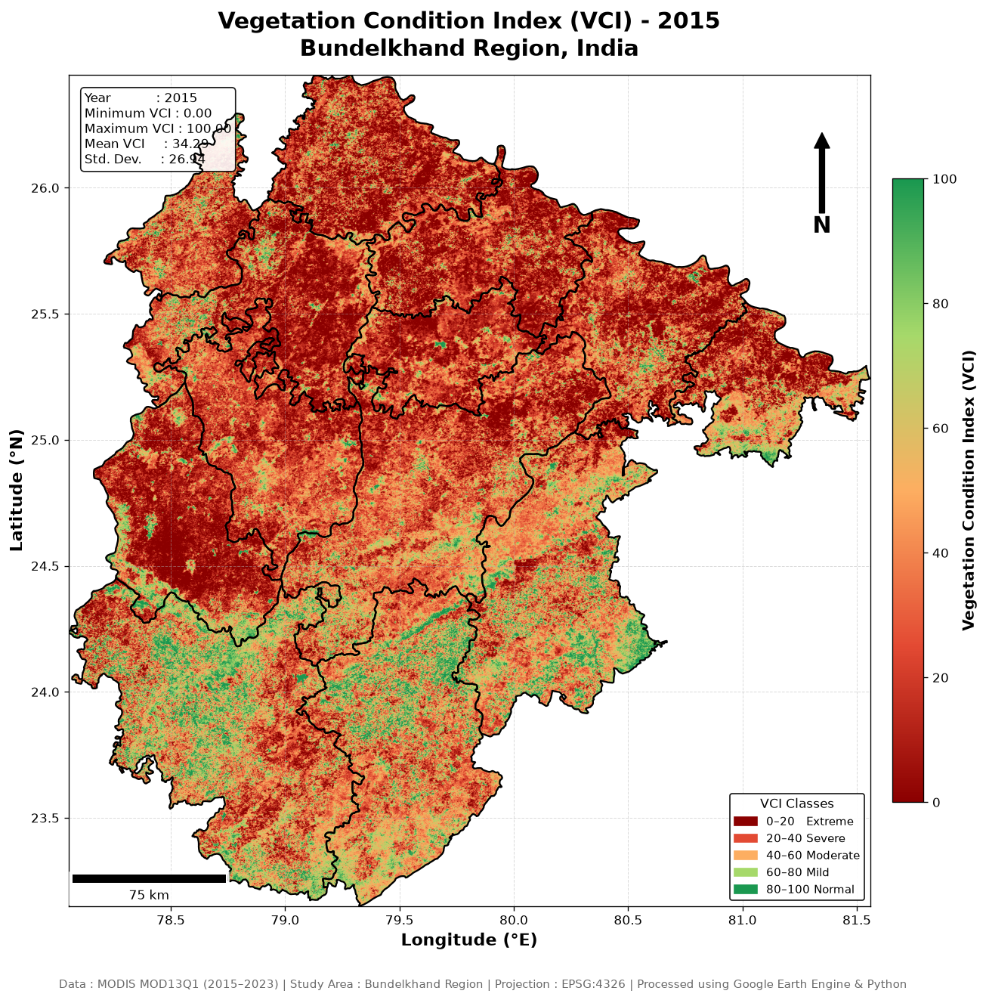

✓ Publication Map Saved : VCI_2015_Publication_Map.png

Generating Publication Map : 2016
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/VCI_2016_Publication_Map.png


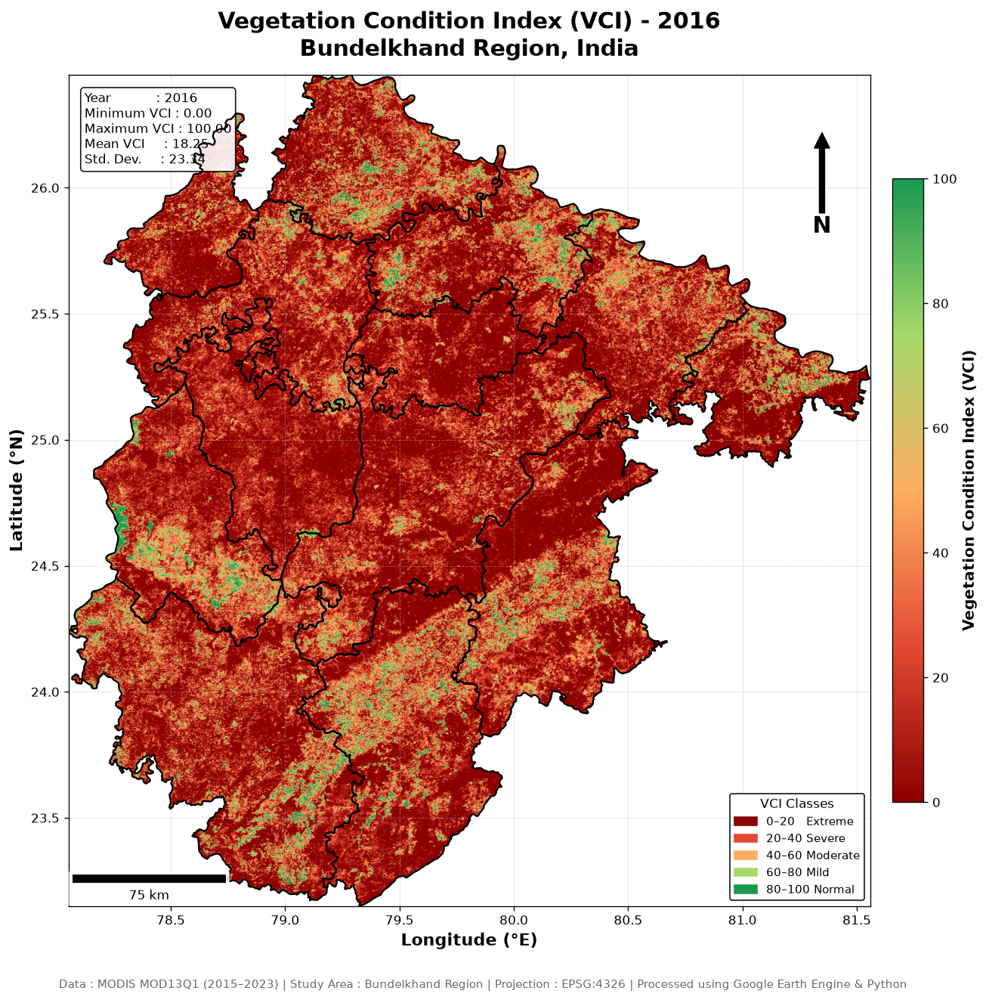

✓ Publication Map Saved : VCI_2016_Publication_Map.png

Generating Publication Map : 2017
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/VCI_2017_Publication_Map.png


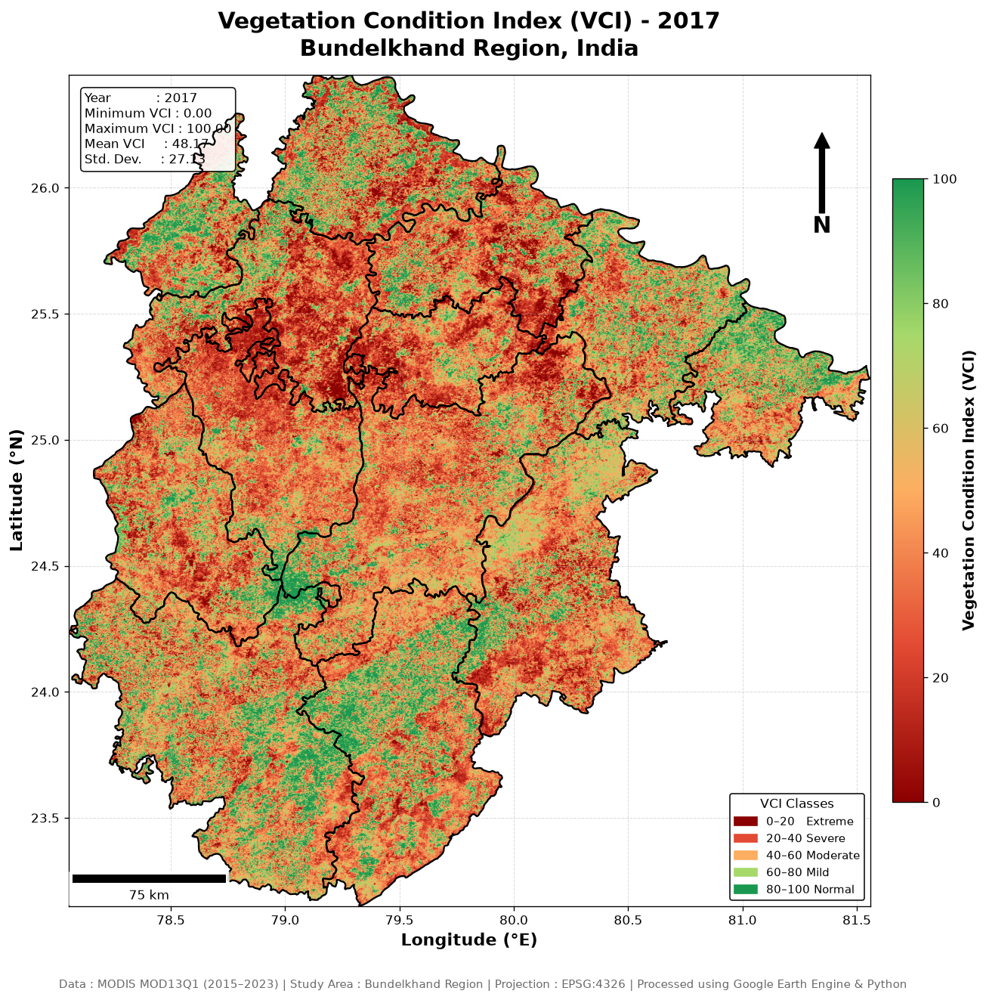

✓ Publication Map Saved : VCI_2017_Publication_Map.png

Generating Publication Map : 2018
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/VCI_2018_Publication_Map.png


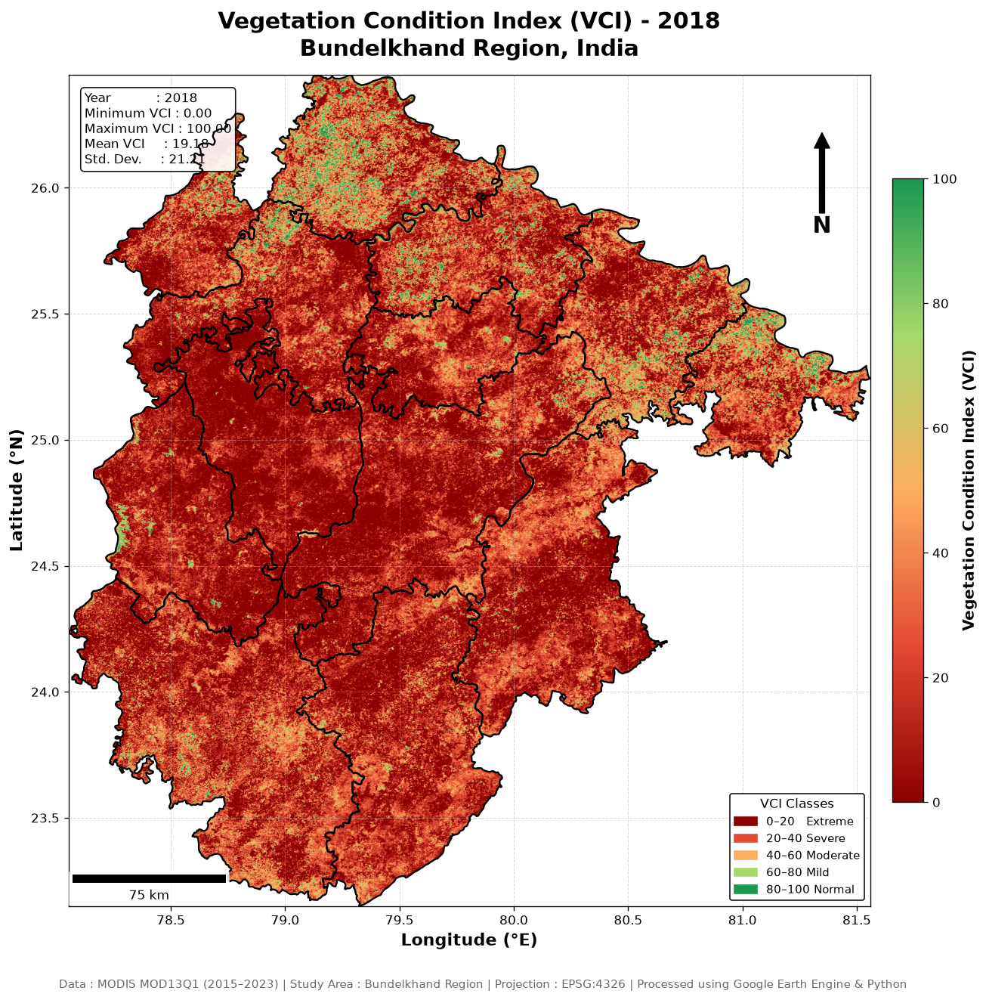

✓ Publication Map Saved : VCI_2018_Publication_Map.png

Generating Publication Map : 2019
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/VCI_2019_Publication_Map.png


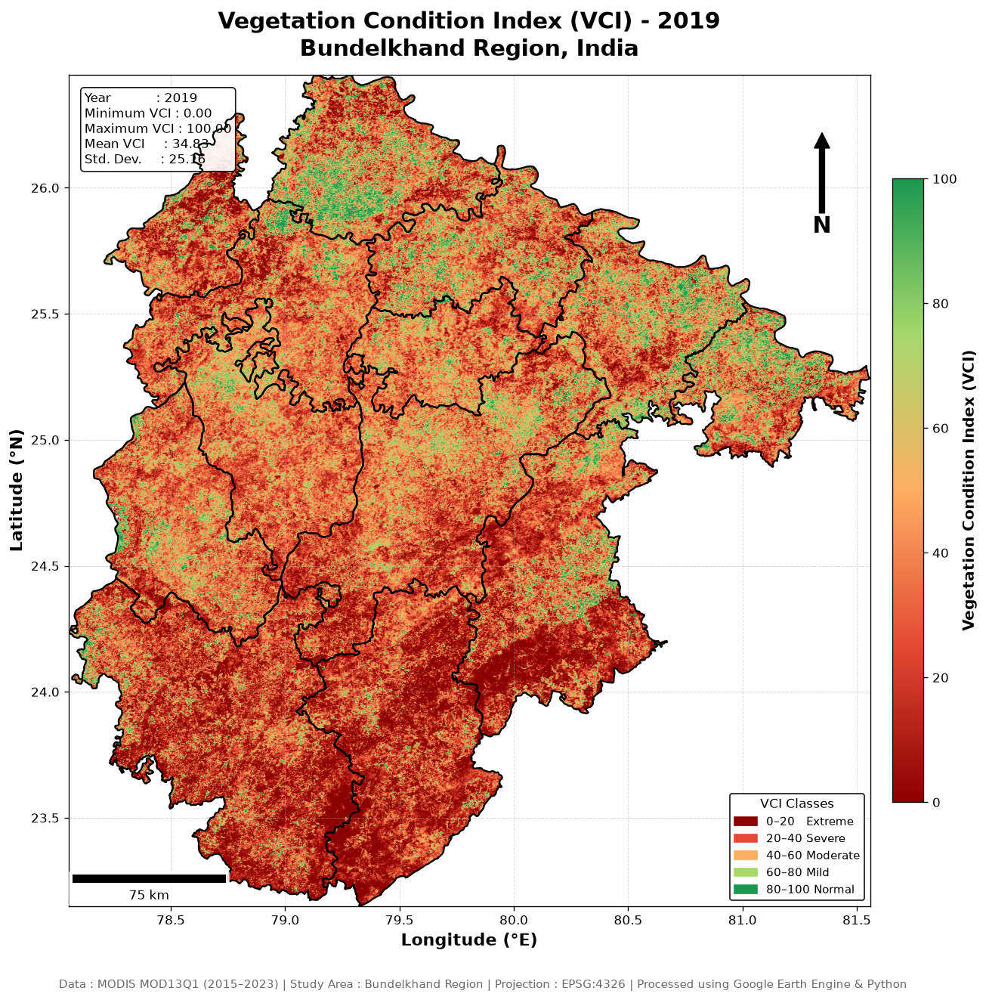

✓ Publication Map Saved : VCI_2019_Publication_Map.png

Generating Publication Map : 2020
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/VCI_2020_Publication_Map.png


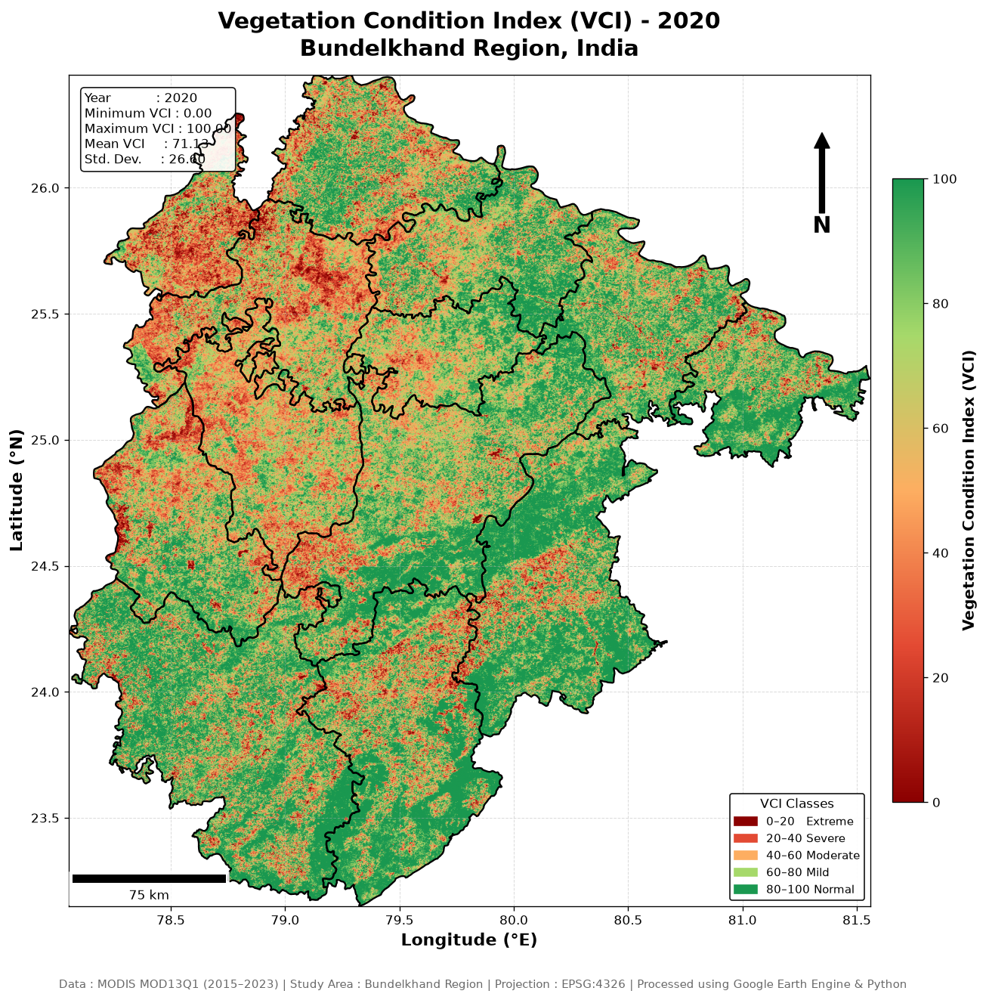

✓ Publication Map Saved : VCI_2020_Publication_Map.png

Generating Publication Map : 2021
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/VCI_2021_Publication_Map.png


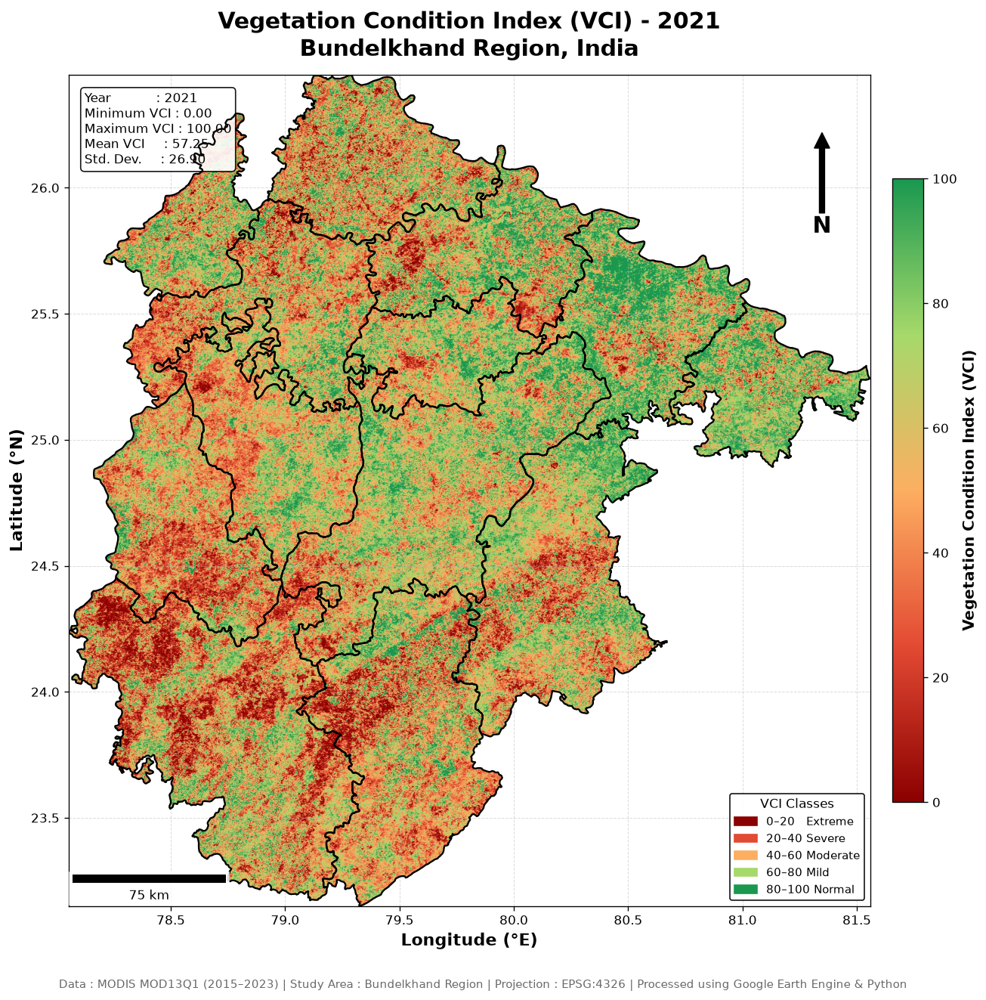

✓ Publication Map Saved : VCI_2021_Publication_Map.png

Generating Publication Map : 2022
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/VCI_2022_Publication_Map.png


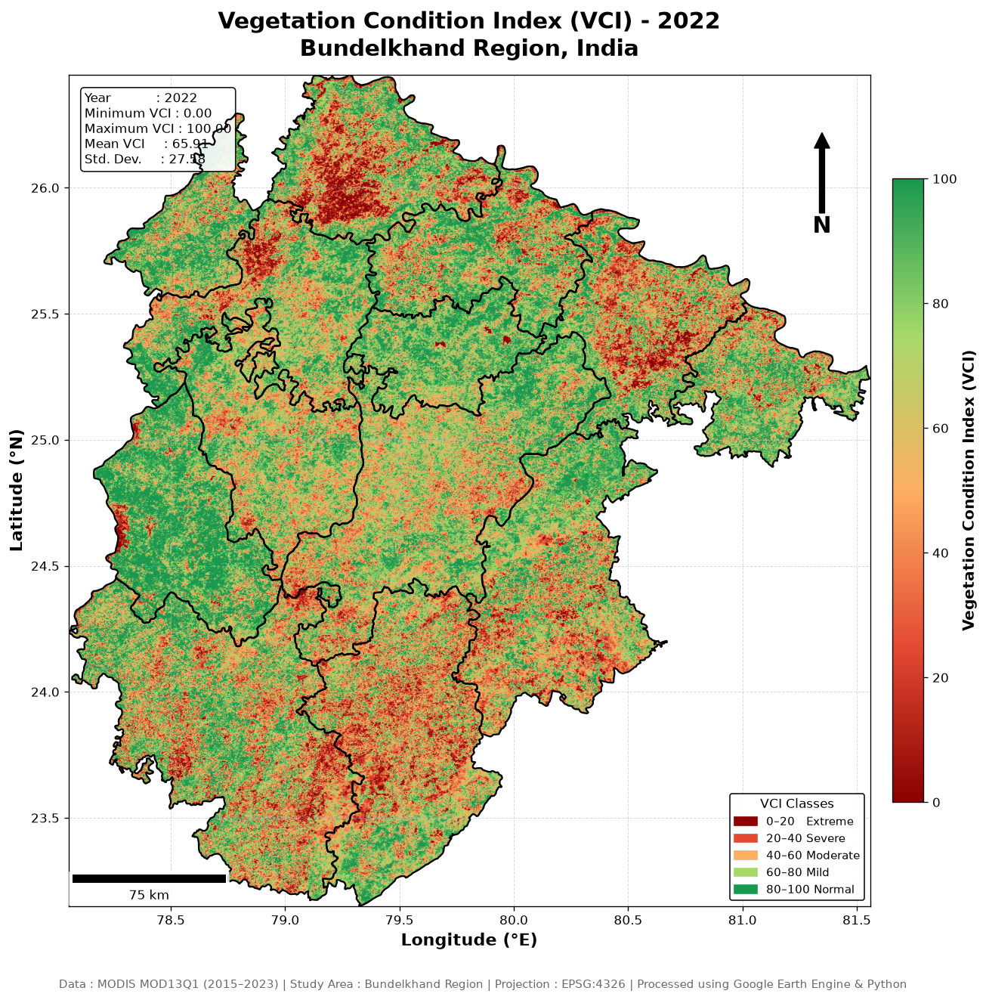

✓ Publication Map Saved : VCI_2022_Publication_Map.png

Generating Publication Map : 2023
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/VCI_2023_Publication_Map.png


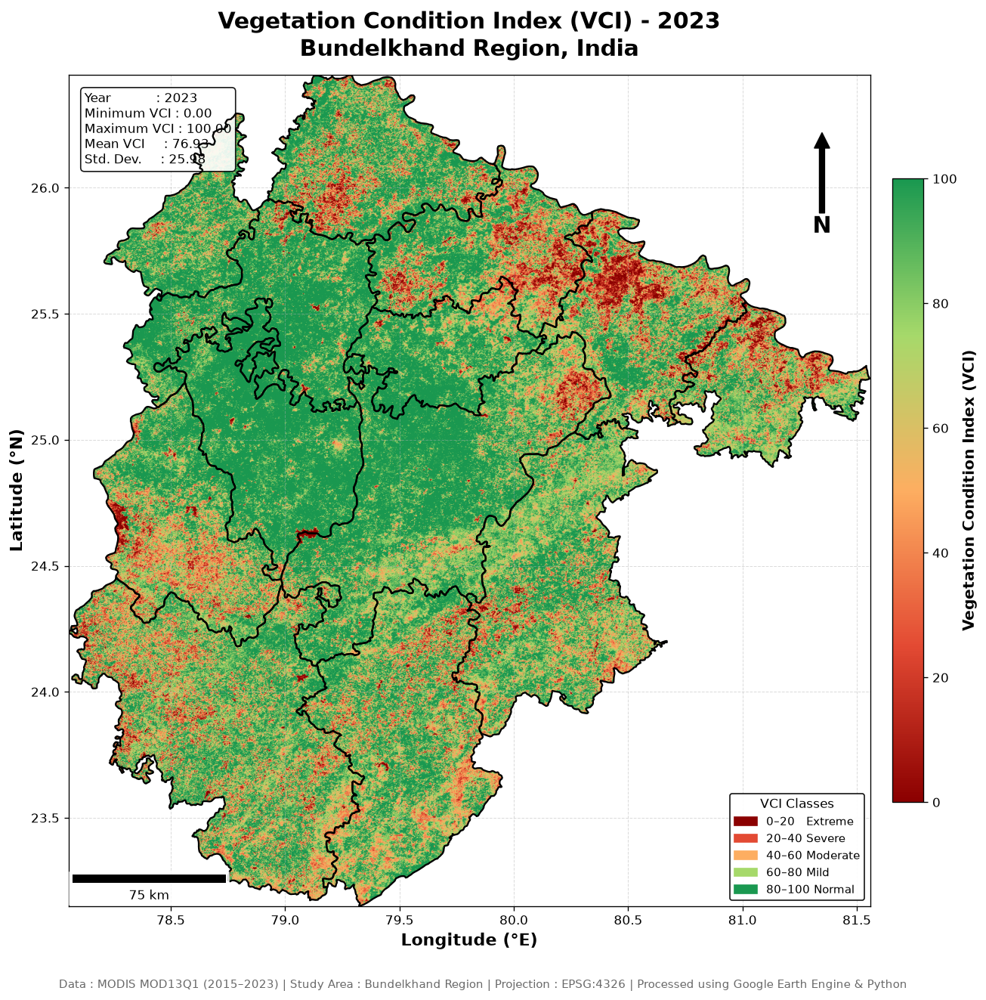

✓ Publication Map Saved : VCI_2023_Publication_Map.png


PUBLICATION QUALITY VCI MAPS GENERATED SUCCESSFULLY
Study Area            : Bundelkhand Region
Study Period          : 2015–2023
Total Maps Generated  : 9
Output Directory      : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps

Generated Maps

✓ VCI_2015_Publication_Map.png
✓ VCI_2016_Publication_Map.png
✓ VCI_2017_Publication_Map.png
✓ VCI_2018_Publication_Map.png
✓ VCI_2019_Publication_Map.png
✓ VCI_2020_Publication_Map.png
✓ VCI_2021_Publication_Map.png
✓ VCI_2022_Publication_Map.png
✓ VCI_2023_Publication_Map.png


VCI VISUALIZATION COMPLETED


In [28]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 7C : Publication Quality VCI Maps (Part 1)
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("GENERATING PUBLICATION QUALITY VCI MAPS")
print("=" * 90)

from matplotlib.colors import LinearSegmentedColormap
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib.patches as mpatches

# ---------------------------------------------------------------
# Professional VCI Colour Palette
# ---------------------------------------------------------------

vci_cmap = LinearSegmentedColormap.from_list(

    "VCI",

    [

        "#8B0000",   # Extreme Drought

        "#E34A33",   # Severe Drought

        "#FDAE61",   # Moderate Drought

        "#A6D96A",   # Mild Drought

        "#1A9850"    # Healthy Vegetation

    ]

)

# ---------------------------------------------------------------
# Raster Extent
# ---------------------------------------------------------------

extent = [

    bounds.left,

    bounds.right,

    bounds.bottom,

    bounds.top

]

# ---------------------------------------------------------------
# Loop Through Every Year
# ---------------------------------------------------------------

for i, year in enumerate(years):

    print(f"\nGenerating Publication Map : {year}")

    vci = vci_stack[i]

    # -----------------------------------------------------------
    # Calculate Statistics
    # -----------------------------------------------------------

    vci_min = np.nanmin(vci)

    vci_max = np.nanmax(vci)

    vci_mean = np.nanmean(vci)

    vci_std = np.nanstd(vci)

    # -----------------------------------------------------------
    # Create Figure
    # -----------------------------------------------------------

    fig, ax = plt.subplots(

        figsize=(13,11)

    )

    # -----------------------------------------------------------
    # Plot Raster
    # -----------------------------------------------------------

    image = ax.imshow(

        vci,

        cmap=vci_cmap,

        extent=extent,

        origin="upper",

        vmin=0,

        vmax=100

    )

    # -----------------------------------------------------------
    # Overlay AOI Boundary
    # -----------------------------------------------------------

    aoi.boundary.plot(

        ax=ax,

        edgecolor="black",

        linewidth=1.4,

        zorder=5

    )

    # -----------------------------------------------------------
    # Title
    # -----------------------------------------------------------

    ax.set_title(

        f"Vegetation Condition Index (VCI) - {year}\n"
        "Bundelkhand Region, India",

        fontsize=18,

        fontweight="bold",

        pad=15

    )

    # -----------------------------------------------------------
    # Axis Labels
    # -----------------------------------------------------------

    ax.set_xlabel(

        "Longitude (°E)",

        fontsize=13,

        fontweight="bold"

    )

    ax.set_ylabel(

        "Latitude (°N)",

        fontsize=13,

        fontweight="bold"

    )

    # -----------------------------------------------------------
    # Coordinate Grid
    # -----------------------------------------------------------

    ax.grid(

        linestyle="--",

        linewidth=0.6,

        alpha=0.45

    )
        # -----------------------------------------------------------
    # Professional Colorbar
    # -----------------------------------------------------------

    cbar = fig.colorbar(

        image,

        ax=ax,

        shrink=0.75,

        pad=0.02

    )

    cbar.set_label(

        "Vegetation Condition Index (VCI)",

        fontsize=12,

        fontweight="bold"

    )

    cbar.ax.tick_params(

        labelsize=10

    )

    # -----------------------------------------------------------
    # North Arrow
    # -----------------------------------------------------------

    ax.annotate(

        "N",

        xy=(0.94,0.93),

        xytext=(0.94,0.81),

        xycoords=ax.transAxes,

        ha="center",

        fontsize=18,

        fontweight="bold",

        arrowprops=dict(

            facecolor="black",

            edgecolor="black",

            width=4,

            headwidth=12,

            headlength=12

        )

    )

    # -----------------------------------------------------------
    # Scale Bar
    #
    # NOTE:
    # Since the raster is in EPSG:4326 this is an approximate
    # scale for visualization.
    # -----------------------------------------------------------

    scalebar = ScaleBar(

        dx=111320,

        units="m",

        location="lower left",

        length_fraction=0.25,

        box_alpha=0.75,

        color="black",

        scale_loc="bottom"

    )

    ax.add_artist(scalebar)

    # -----------------------------------------------------------
    # Statistics Box
    # -----------------------------------------------------------

    statistics = (

        f"Year            : {year}\n"

        f"Minimum VCI : {vci_min:.2f}\n"

        f"Maximum VCI : {vci_max:.2f}\n"

        f"Mean VCI     : {vci_mean:.2f}\n"

        f"Std. Dev.     : {vci_std:.2f}"

    )

    ax.text(

        0.02,

        0.98,

        statistics,

        transform=ax.transAxes,

        fontsize=10,

        verticalalignment="top",

        bbox=dict(

            facecolor="white",

            edgecolor="black",

            alpha=0.90,

            boxstyle="round"

        )

    )

    # -----------------------------------------------------------
    # VCI Legend
    # -----------------------------------------------------------

    legend_items = [

        mpatches.Patch(color="#8B0000", label="0–20   Extreme"),

        mpatches.Patch(color="#E34A33", label="20–40 Severe"),

        mpatches.Patch(color="#FDAE61", label="40–60 Moderate"),

        mpatches.Patch(color="#A6D96A", label="60–80 Mild"),

        mpatches.Patch(color="#1A9850", label="80–100 Normal")

    ]

    legend = ax.legend(

        handles=legend_items,

        title="VCI Classes",

        loc="lower right",

        fontsize=9,

        title_fontsize=10,

        frameon=True,

        edgecolor="black"

    )

    legend.get_frame().set_alpha(0.92)

    # -----------------------------------------------------------
    # Tick Formatting
    # -----------------------------------------------------------

    ax.tick_params(

        axis="both",

        labelsize=10

    )
        # -----------------------------------------------------------
    # Footer
    # -----------------------------------------------------------

    plt.figtext(

        0.5,

        0.005,

        "Data : MODIS MOD13Q1 (2015–2023) | Study Area : Bundelkhand Region | "
        "Projection : EPSG:4326 | Processed using Google Earth Engine & Python",

        ha="center",

        fontsize=9,

        color="dimgray"

    )

    # -----------------------------------------------------------
    # Tight Layout
    # -----------------------------------------------------------

    plt.tight_layout(

        rect=[0, 0.03, 1, 1]

    )

    # -----------------------------------------------------------
    # Save Publication Figure
    # -----------------------------------------------------------

    save_figure(

        filename=f"VCI_{year}_Publication_Map.png",

        folder=MAP_DIR,

        dpi=300

    )

    # -----------------------------------------------------------
    # Display Figure
    # -----------------------------------------------------------

    plt.show()

    # -----------------------------------------------------------
    # Close Figure (Prevents Memory Leakage)
    # -----------------------------------------------------------

    plt.close(fig)

    print(f"✓ Publication Map Saved : VCI_{year}_Publication_Map.png")

# ===============================================================
# Final Summary
# ===============================================================

print("\n")

print("=" * 90)
print("PUBLICATION QUALITY VCI MAPS GENERATED SUCCESSFULLY")
print("=" * 90)

print(f"Study Area            : Bundelkhand Region")

print(f"Study Period          : {years[0]}–{years[-1]}")

print(f"Total Maps Generated  : {len(years)}")

print(f"Output Directory      : {MAP_DIR}")

print("=" * 90)

# ---------------------------------------------------------------
# Display Output Files
# ---------------------------------------------------------------

print("\nGenerated Maps\n")

for year in years:

    print(f"✓ VCI_{year}_Publication_Map.png")

print("\n")

print("=" * 90)
print("VCI VISUALIZATION COMPLETED")
print("=" * 90)

In [29]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 8A : Drought Severity Classification
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("DROUGHT SEVERITY CLASSIFICATION")
print("=" * 90)

# ---------------------------------------------------------------
# Drought Class Labels
# ---------------------------------------------------------------

drought_labels = {

    1: "Extreme Drought",

    2: "Severe Drought",

    3: "Moderate Drought",

    4: "Mild Drought",

    5: "Normal"

}

# ---------------------------------------------------------------
# Color Palette
# ---------------------------------------------------------------

drought_colors = [

    "#8B0000",      # Extreme

    "#E34A33",      # Severe

    "#FDAE61",      # Moderate

    "#A6D96A",      # Mild

    "#1A9850"       # Normal

]

# ---------------------------------------------------------------
# Containers
# ---------------------------------------------------------------

drought_stack = []

drought_statistics = []

# ---------------------------------------------------------------
# Classification Loop
# ---------------------------------------------------------------

for i, year in enumerate(years):

    print(f"Classifying : {year}")

    vci = vci_stack[i]

    drought = np.full(

        vci.shape,

        np.nan,

        dtype=np.float32

    )

    # -----------------------------------------------------------
    # Classification
    # -----------------------------------------------------------

    drought[(vci >= 0) & (vci < 20)] = 1

    drought[(vci >= 20) & (vci < 40)] = 2

    drought[(vci >= 40) & (vci < 60)] = 3

    drought[(vci >= 60) & (vci < 80)] = 4

    drought[(vci >= 80)] = 5

    drought_stack.append(drought)

    # -----------------------------------------------------------
    # Pixel Count
    # -----------------------------------------------------------

    stats = {

        "Year": year,

        "Extreme": np.sum(drought == 1),

        "Severe": np.sum(drought == 2),

        "Moderate": np.sum(drought == 3),

        "Mild": np.sum(drought == 4),

        "Normal": np.sum(drought == 5)

    }

    drought_statistics.append(stats)

# ---------------------------------------------------------------
# Convert to NumPy Stack
# ---------------------------------------------------------------

drought_stack = np.stack(drought_stack)

drought_statistics = pd.DataFrame(

    drought_statistics

)

# ---------------------------------------------------------------
# Display Statistics
# ---------------------------------------------------------------

display(drought_statistics)

print("=" * 90)

print("Classification Completed")

print("=" * 90)

# ---------------------------------------------------------------
# Save Complete Stack
# ---------------------------------------------------------------

save_numpy(

    drought_stack,

    "Drought_Classification_Stack.npy"

)

save_csv(

    drought_statistics,

    "Drought_Class_Pixel_Count.csv"

)

print("Classification Stack Saved")

print("=" * 90)

DROUGHT SEVERITY CLASSIFICATION
Classifying : 2015
Classifying : 2016
Classifying : 2017
Classifying : 2018
Classifying : 2019
Classifying : 2020
Classifying : 2021
Classifying : 2022
Classifying : 2023


,Year,Extreme,Severe,Moderate,Mild,Normal
0,2015,438269,333324,259048,133699,88020
1,2016,814770,230216,117876,53110,36372
2,2017,190279,344144,330365,195080,192492
3,2018,756998,298234,129918,44291,22919
4,2019,391619,376764,280169,131945,71789
5,2020,51502,134835,235865,271715,558442
6,2021,122123,217458,323363,305653,283763
7,2022,87621,150159,255738,301959,456883
8,2023,50754,85635,167462,251548,696961


Classification Completed
NumPy Array Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/Drought_Classification_Stack.npy
CSV Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Tables/Drought_Class_Pixel_Count.csv
Classification Stack Saved


In [30]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 8B : Export Drought Classification & Area Statistics
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("EXPORTING DROUGHT CLASSIFICATION PRODUCTS")
print("=" * 90)

# ---------------------------------------------------------------
# Calculate Pixel Area (km²)
# ---------------------------------------------------------------

with rasterio.open(ndvi_files[0]) as src:

    transform = src.transform

    pixel_width = abs(transform.a)

    pixel_height = abs(transform.e)

# ---------------------------------------------------------------
# Approximate Pixel Area
# (Suitable for EPSG:4326 exported from GEE at 250 m)
# ---------------------------------------------------------------

PIXEL_AREA_KM2 = (250 * 250) / 1_000_000

print(f"Pixel Area : {PIXEL_AREA_KM2:.5f} km²")

# ---------------------------------------------------------------
# Area Statistics Container
# ---------------------------------------------------------------

area_statistics = []

# ---------------------------------------------------------------
# Export Each Classified Raster
# ---------------------------------------------------------------

for i, year in enumerate(years):

    drought = drought_stack[i]

    print(f"\nProcessing {year}")

    # -----------------------------------------------------------
    # Save Classified GeoTIFF
    # -----------------------------------------------------------

    save_classified_raster(

        array=drought,

        metadata=raster_meta,

        filename=f"Drought_{year}.tif"

    )

    # -----------------------------------------------------------
    # Area Statistics
    # -----------------------------------------------------------

    extreme_pixels = np.sum(drought == 1)

    severe_pixels = np.sum(drought == 2)

    moderate_pixels = np.sum(drought == 3)

    mild_pixels = np.sum(drought == 4)

    normal_pixels = np.sum(drought == 5)

    area_statistics.append({

        "Year": year,

        "Extreme_km2":
            extreme_pixels * PIXEL_AREA_KM2,

        "Severe_km2":
            severe_pixels * PIXEL_AREA_KM2,

        "Moderate_km2":
            moderate_pixels * PIXEL_AREA_KM2,

        "Mild_km2":
            mild_pixels * PIXEL_AREA_KM2,

        "Normal_km2":
            normal_pixels * PIXEL_AREA_KM2

    })

# ---------------------------------------------------------------
# Convert to DataFrame
# ---------------------------------------------------------------

area_statistics = pd.DataFrame(area_statistics)

# ---------------------------------------------------------------
# Display Results
# ---------------------------------------------------------------

display(area_statistics)

# ---------------------------------------------------------------
# Save CSV
# ---------------------------------------------------------------

save_csv(

    area_statistics,

    "Drought_Area_Statistics.csv"

)

print("\nArea Statistics Saved Successfully.")

# ---------------------------------------------------------------
# Summary
# ---------------------------------------------------------------

print("\n")

print("=" * 90)

print("DROUGHT CLASSIFICATION EXPORT COMPLETED")

print("=" * 90)

print(f"Years Processed      : {len(years)}")

print(f"GeoTIFF Exported     : {len(years)}")

print(f"Statistics File      : Drought_Area_Statistics.csv")

print("=" * 90)

# ---------------------------------------------------------------
# Display Output Structure
# ---------------------------------------------------------------

print("\nGenerated Outputs\n")

print("results/")

print("│")

print("├── Raster/")

for year in years:

    print(f"│     ├── Drought_{year}.tif")

print("│")

print("├── Tables/")

print("│     ├── Drought_Class_Pixel_Count.csv")

print("│     └── Drought_Area_Statistics.csv")

print("\n")

print("=" * 90)
print("AREA STATISTICS GENERATED SUCCESSFULLY")
print("=" * 90)

EXPORTING DROUGHT CLASSIFICATION PRODUCTS
Pixel Area : 0.06250 km²

Processing 2015
Classified Raster Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/Drought_2015.tif

Processing 2016
Classified Raster Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/Drought_2016.tif

Processing 2017
Classified Raster Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/Drought_2017.tif

Processing 2018
Classified Raster Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/Drought_2018.tif

Processing 2019
Classified Raster Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Raster/Drought_2019.tif

Processing 2020
Classified Raster Saved : /home/mina

,Year,Extreme_km2,Severe_km2,Moderate_km2,Mild_km2,Normal_km2
0,2015,27391.8125,20832.7500,16190.5000,8356.1875,5501.2500
1,2016,50923.1250,14388.5000,7367.2500,3319.3750,2273.2500
2,2017,11892.4375,21509.0000,20647.8125,12192.5000,12030.7500
3,2018,47312.3750,18639.6250,8119.8750,2768.1875,1432.4375
4,2019,24476.1875,23547.7500,17510.5625,8246.5625,4486.8125
5,2020,3218.8750,8427.1875,14741.5625,16982.1875,34902.6250
6,2021,7632.6875,13591.1250,20210.1875,19103.3125,17735.1875
7,2022,5476.3125,9384.9375,15983.6250,18872.4375,28555.1875
8,2023,3172.1250,5352.1875,10466.3750,15721.7500,43560.0625


CSV Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Tables/Drought_Area_Statistics.csv

Area Statistics Saved Successfully.


DROUGHT CLASSIFICATION EXPORT COMPLETED
Years Processed      : 9
GeoTIFF Exported     : 9
Statistics File      : Drought_Area_Statistics.csv

Generated Outputs

results/
│
├── Raster/
│     ├── Drought_2015.tif
│     ├── Drought_2016.tif
│     ├── Drought_2017.tif
│     ├── Drought_2018.tif
│     ├── Drought_2019.tif
│     ├── Drought_2020.tif
│     ├── Drought_2021.tif
│     ├── Drought_2022.tif
│     ├── Drought_2023.tif
│
├── Tables/
│     ├── Drought_Class_Pixel_Count.csv
│     └── Drought_Area_Statistics.csv


AREA STATISTICS GENERATED SUCCESSFULLY


GENERATING PUBLICATION QUALITY DROUGHT SEVERITY MAPS

Generating Drought Map : 2015
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/Drought_2015_Publication_Map.png


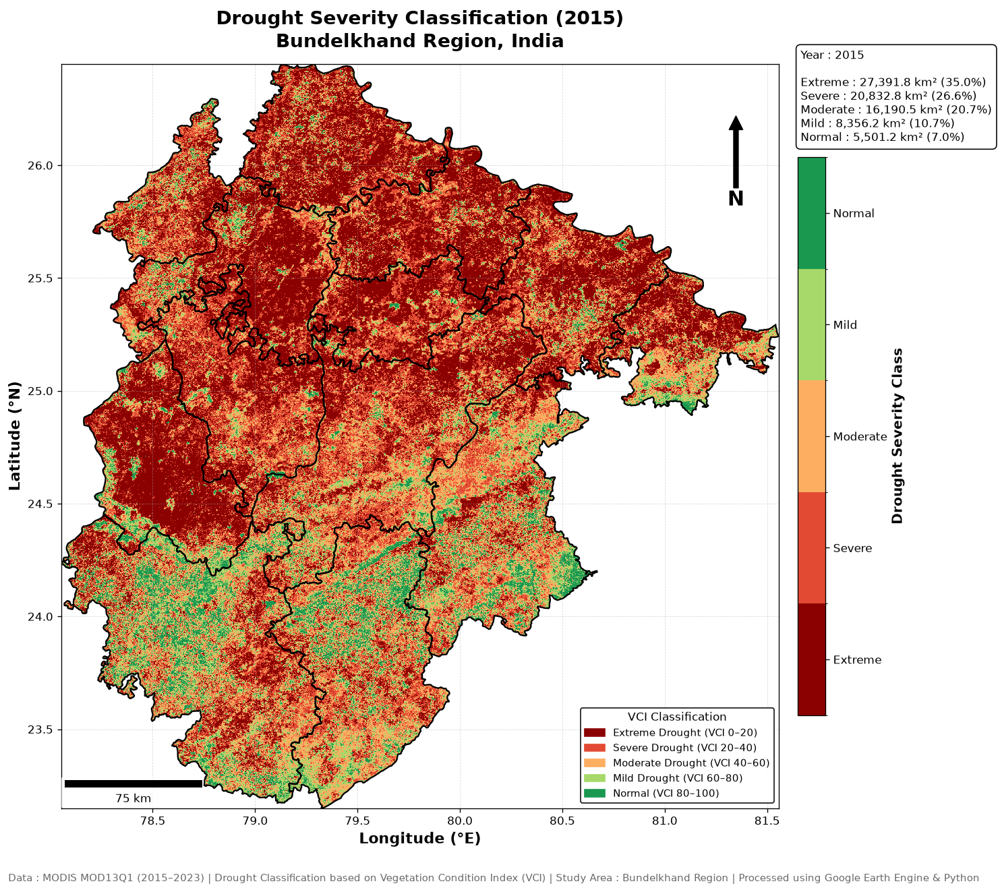

✓ Saved : Drought_2015_Publication_Map.png

Generating Drought Map : 2016
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/Drought_2016_Publication_Map.png


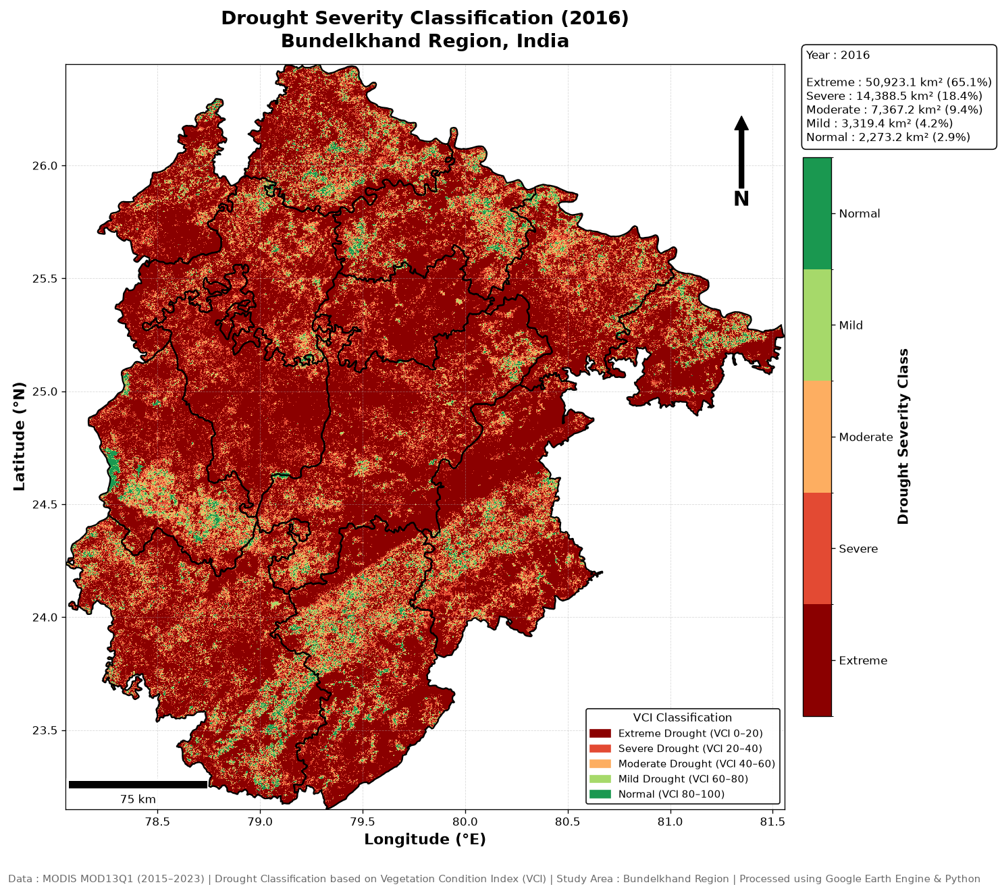

✓ Saved : Drought_2016_Publication_Map.png

Generating Drought Map : 2017
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/Drought_2017_Publication_Map.png


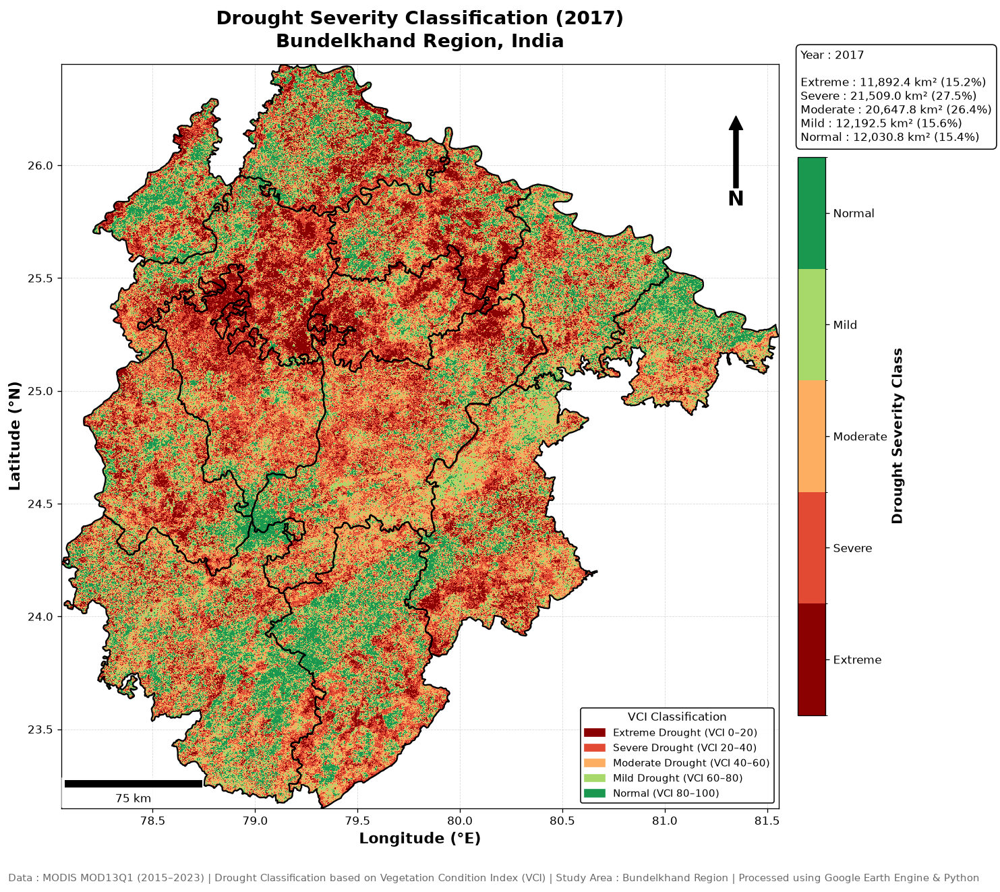

✓ Saved : Drought_2017_Publication_Map.png

Generating Drought Map : 2018
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/Drought_2018_Publication_Map.png


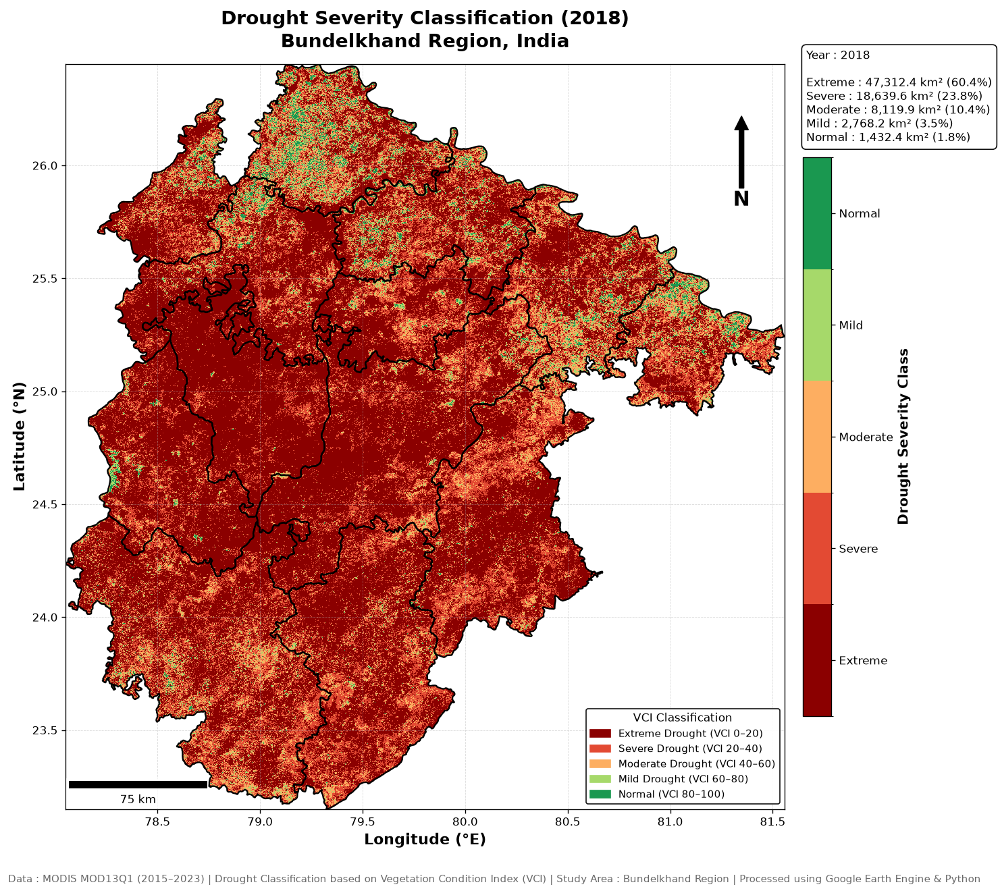

✓ Saved : Drought_2018_Publication_Map.png

Generating Drought Map : 2019
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/Drought_2019_Publication_Map.png


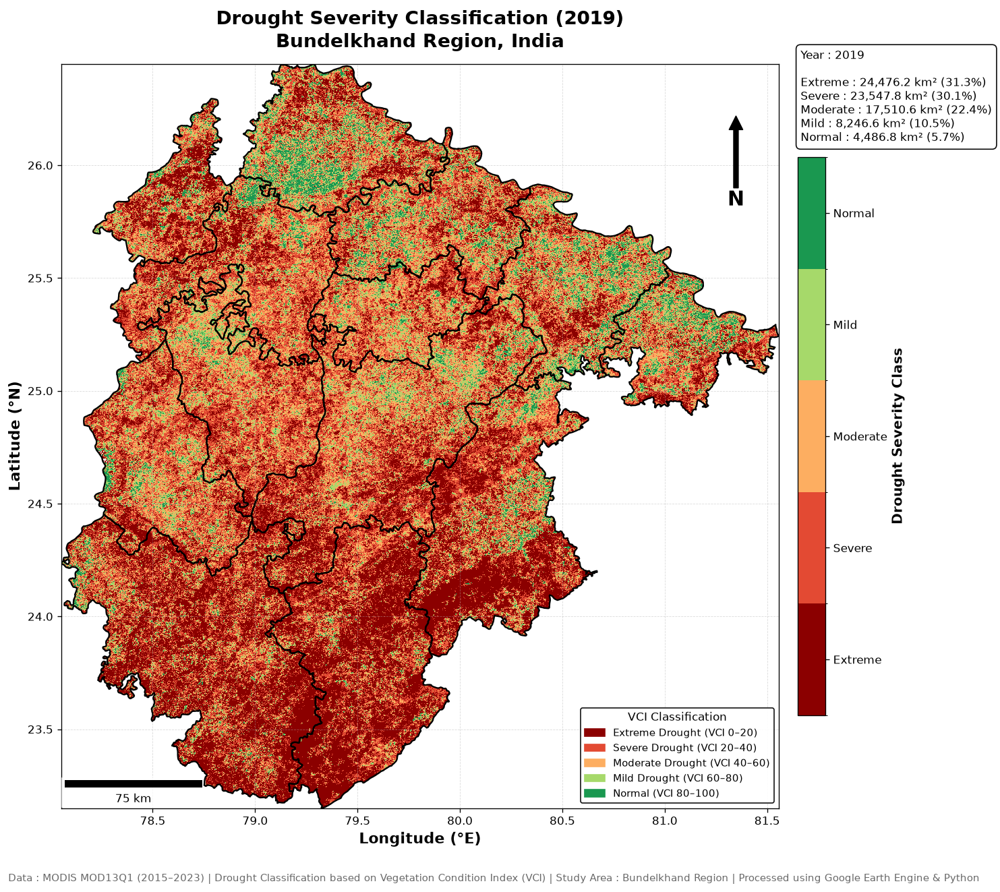

✓ Saved : Drought_2019_Publication_Map.png

Generating Drought Map : 2020
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/Drought_2020_Publication_Map.png


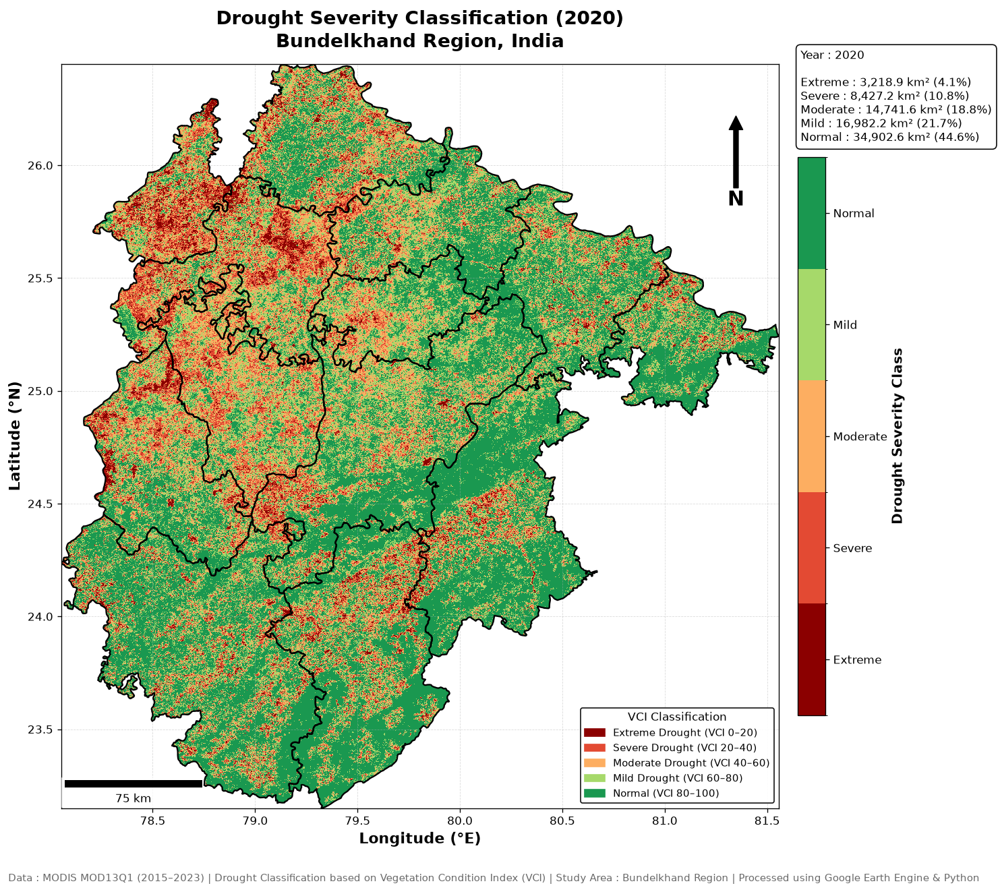

✓ Saved : Drought_2020_Publication_Map.png

Generating Drought Map : 2021
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/Drought_2021_Publication_Map.png


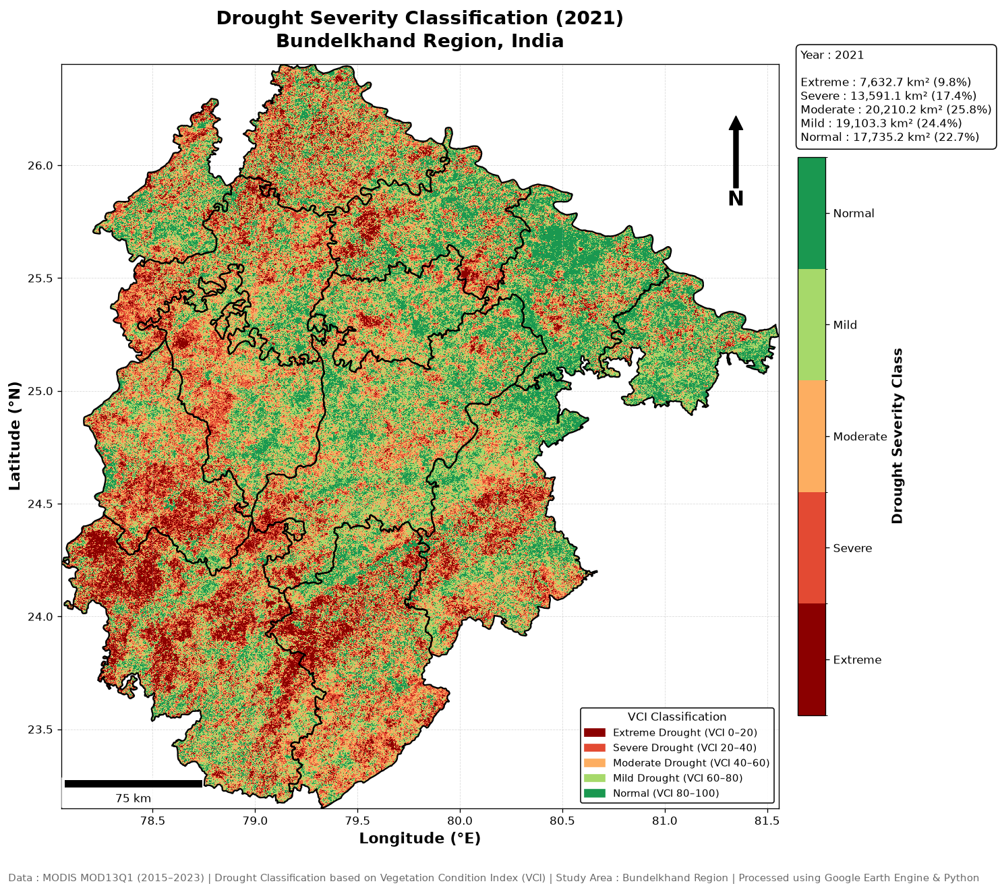

✓ Saved : Drought_2021_Publication_Map.png

Generating Drought Map : 2022
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/Drought_2022_Publication_Map.png


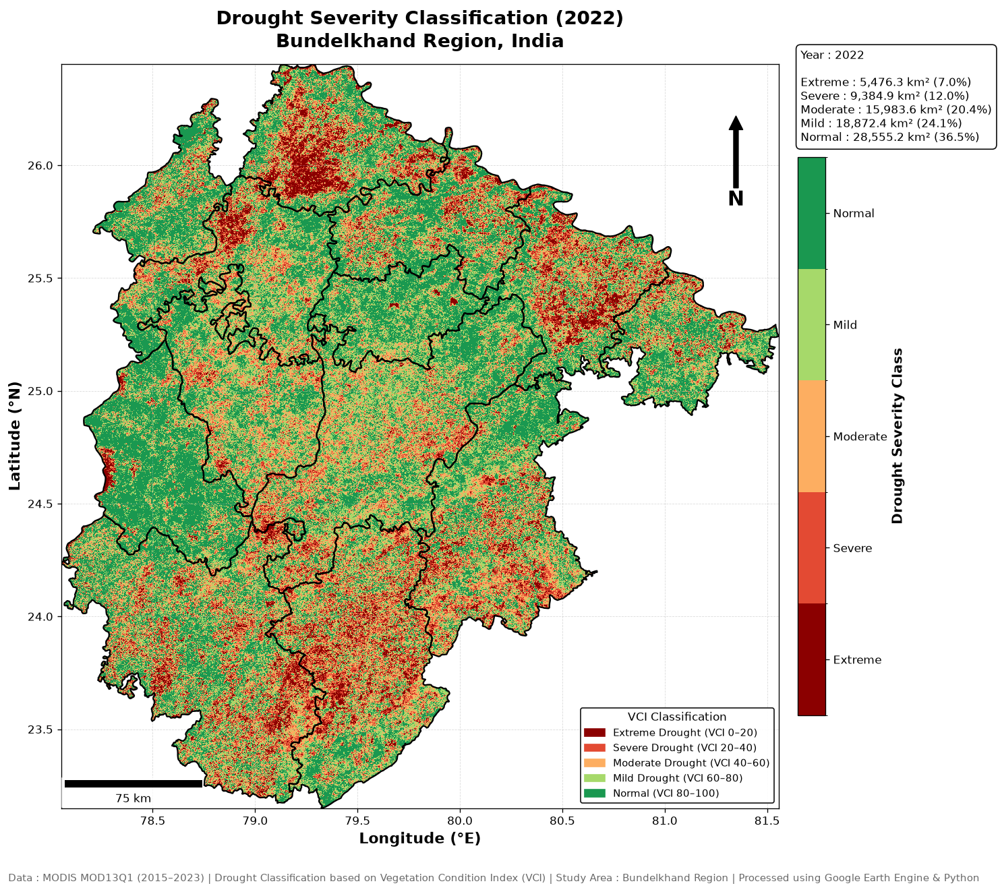

✓ Saved : Drought_2022_Publication_Map.png

Generating Drought Map : 2023
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps/Drought_2023_Publication_Map.png


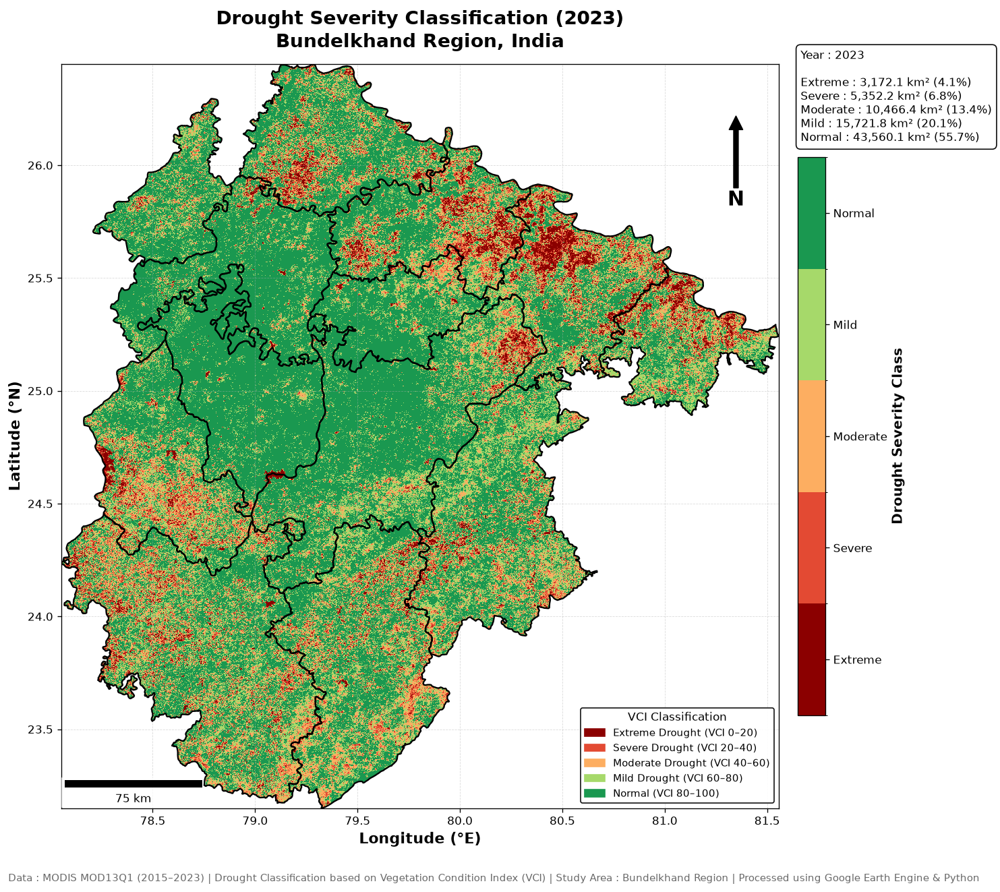

✓ Saved : Drought_2023_Publication_Map.png


DROUGHT SEVERITY MAPPING COMPLETED SUCCESSFULLY
Study Area            : Bundelkhand Region
Study Period          : 2015–2023
Maps Generated        : 9
Classification Method : Vegetation Condition Index (VCI)
Output Directory      : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Maps

Generated Maps

✓ Drought_2015_Publication_Map.png
✓ Drought_2016_Publication_Map.png
✓ Drought_2017_Publication_Map.png
✓ Drought_2018_Publication_Map.png
✓ Drought_2019_Publication_Map.png
✓ Drought_2020_Publication_Map.png
✓ Drought_2021_Publication_Map.png
✓ Drought_2022_Publication_Map.png
✓ Drought_2023_Publication_Map.png


PROJECT STATUS
✓ Annual NDVI Stack
✓ NDVI Minimum Raster
✓ NDVI Maximum Raster
✓ Vegetation Condition Index (VCI)
✓ Drought Severity Classification
✓ Publication-quality Drought Maps

Drought Area Statistics (km²)



,Year,Extreme_km2,Severe_km2,Moderate_km2,Mild_km2,Normal_km2
0,2015,27391.8125,20832.7500,16190.5000,8356.1875,5501.2500
1,2016,50923.1250,14388.5000,7367.2500,3319.3750,2273.2500
2,2017,11892.4375,21509.0000,20647.8125,12192.5000,12030.7500
3,2018,47312.3750,18639.6250,8119.8750,2768.1875,1432.4375
4,2019,24476.1875,23547.7500,17510.5625,8246.5625,4486.8125
5,2020,3218.8750,8427.1875,14741.5625,16982.1875,34902.6250
6,2021,7632.6875,13591.1250,20210.1875,19103.3125,17735.1875
7,2022,5476.3125,9384.9375,15983.6250,18872.4375,28555.1875
8,2023,3172.1250,5352.1875,10466.3750,15721.7500,43560.0625


CELL 8 COMPLETED


In [43]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 8C : Publication Quality Drought Maps (Part 1)
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("GENERATING PUBLICATION QUALITY DROUGHT SEVERITY MAPS")
print("=" * 90)

from matplotlib.colors import ListedColormap
from matplotlib.colors import BoundaryNorm
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib.patches as mpatches

# ---------------------------------------------------------------
# Professional Drought Colour Palette
# ---------------------------------------------------------------

drought_cmap = ListedColormap([

    "#8B0000",      # 1 Extreme Drought

    "#E34A33",      # 2 Severe Drought

    "#FDAE61",      # 3 Moderate Drought

    "#A6D96A",      # 4 Mild Drought

    "#1A9850"       # 5 Normal

])

# ---------------------------------------------------------------
# Class Boundaries
# ---------------------------------------------------------------

bounds_class = [

    0.5,

    1.5,

    2.5,

    3.5,

    4.5,

    5.5

]

norm = BoundaryNorm(

    bounds_class,

    drought_cmap.N

)

# ---------------------------------------------------------------
# Raster Extent
# ---------------------------------------------------------------

extent = [

    bounds.left,

    bounds.right,

    bounds.bottom,

    bounds.top

]

# ---------------------------------------------------------------
# Loop Through Every Year
# ---------------------------------------------------------------

for i, year in enumerate(years):

    print(f"\nGenerating Drought Map : {year}")

    drought = drought_stack[i]

    # -----------------------------------------------------------
    # Pixel Count
    # -----------------------------------------------------------

    extreme = np.sum(drought == 1)

    severe = np.sum(drought == 2)

    moderate = np.sum(drought == 3)

    mild = np.sum(drought == 4)

    normal = np.sum(drought == 5)

    total_pixels = (

        extreme +

        severe +

        moderate +

        mild +

        normal

    )

    # -----------------------------------------------------------
    # Area Statistics
    # -----------------------------------------------------------

    extreme_area = extreme * PIXEL_AREA_KM2

    severe_area = severe * PIXEL_AREA_KM2

    moderate_area = moderate * PIXEL_AREA_KM2

    mild_area = mild * PIXEL_AREA_KM2

    normal_area = normal * PIXEL_AREA_KM2

    # -----------------------------------------------------------
    # Create Figure
    # -----------------------------------------------------------

    fig, ax = plt.subplots(

        figsize=(13,11)

    )

    # -----------------------------------------------------------
    # Plot Classified Raster
    # -----------------------------------------------------------

    image = ax.imshow(

        drought,

        cmap=drought_cmap,

        norm=norm,

        extent=extent,

        origin="upper",

        interpolation="nearest"

    )

    # -----------------------------------------------------------
    # Overlay AOI Boundary
    # -----------------------------------------------------------

    aoi.boundary.plot(

        ax=ax,

        edgecolor="black",

        linewidth=1.4,

        zorder=10

    )

    # -----------------------------------------------------------
    # Title
    # -----------------------------------------------------------

    ax.set_title(

        f"Drought Severity Classification ({year})\n"

        "Bundelkhand Region, India",

        fontsize=17,

        fontweight="bold",

        pad=15

    )

    # -----------------------------------------------------------
    # Axis Labels
    # -----------------------------------------------------------

    ax.set_xlabel(

        "Longitude (°E)",

        fontsize=13,

        fontweight="bold"

    )

    ax.set_ylabel(

        "Latitude (°N)",

        fontsize=13,

        fontweight="bold"

    )

    # -----------------------------------------------------------
    # Grid
    # -----------------------------------------------------------

    ax.grid(

        linestyle="--",

        linewidth=0.5,

        alpha=0.45

    )
        # -----------------------------------------------------------
    # Professional Colorbar
    # -----------------------------------------------------------

    cbar = fig.colorbar(

        image,

        ax=ax,

        shrink=0.75,

        pad=0.02,

        ticks=[1, 2, 3, 4, 5]

    )

    cbar.ax.set_yticklabels([

        "Extreme",

        "Severe",

        "Moderate",

        "Mild",

        "Normal"

    ])

    cbar.set_label(

        "Drought Severity Class",

        fontsize=12,

        fontweight="bold"

    )

    cbar.ax.tick_params(

        labelsize=10

    )

    # -----------------------------------------------------------
    # North Arrow
    # -----------------------------------------------------------

    ax.annotate(

        "N",

        xy=(0.94,0.93),

        xytext=(0.94,0.81),

        xycoords=ax.transAxes,

        ha="center",

        fontsize=18,

        fontweight="bold",

        arrowprops=dict(

            facecolor="black",

            edgecolor="black",

            width=4,

            headwidth=12,

            headlength=12

        )

    )

    # -----------------------------------------------------------
    # Scale Bar
    # -----------------------------------------------------------

    scalebar = ScaleBar(

        dx=111320,

        units="m",

        location="lower left",

        length_fraction=0.25,

        box_alpha=0.75,

        color="black",

        scale_loc="bottom"

    )

    ax.add_artist(scalebar)

    # -----------------------------------------------------------
    # Percentage Calculation
    # -----------------------------------------------------------

    extreme_pct = (extreme / total_pixels) * 100

    severe_pct = (severe / total_pixels) * 100

    moderate_pct = (moderate / total_pixels) * 100

    mild_pct = (mild / total_pixels) * 100

    normal_pct = (normal / total_pixels) * 100

    # -----------------------------------------------------------
    # Area Statistics Box
    # -----------------------------------------------------------
     
    statistics = (

        f"Year : {year}\n\n"

        f"Extreme : {extreme_area:,.1f} km² ({extreme_pct:.1f}%)\n"

        f"Severe : {severe_area:,.1f} km² ({severe_pct:.1f}%)\n"

        f"Moderate : {moderate_area:,.1f} km² ({moderate_pct:.1f}%)\n"

        f"Mild : {mild_area:,.1f} km² ({mild_pct:.1f}%)\n"

        f"Normal : {normal_area:,.1f} km² ({normal_pct:.1f}%)"

    )

    ax.text(

        1.03,

        1.02,

        statistics,

        transform=ax.transAxes,

        fontsize=10,

        ha="left",

        va="top",

        bbox=dict(

            facecolor="white",

            edgecolor="black",

            boxstyle="round,pad=0.4",

            alpha=0.95

        )

    )
    # -----------------------------------------------------------
    # Professional Legend
    # -----------------------------------------------------------

    legend_items = [

        mpatches.Patch(

            color="#8B0000",

            label="Extreme Drought (VCI 0–20)"

        ),

        mpatches.Patch(

            color="#E34A33",

            label="Severe Drought (VCI 20–40)"

        ),

        mpatches.Patch(

            color="#FDAE61",

            label="Moderate Drought (VCI 40–60)"

        ),

        mpatches.Patch(

            color="#A6D96A",

            label="Mild Drought (VCI 60–80)"

        ),

        mpatches.Patch(

            color="#1A9850",

            label="Normal (VCI 80–100)"

        )

    ]

    legend = ax.legend(

        handles=legend_items,

        title="VCI Classification",

        loc="lower right",

        fontsize=9,

        title_fontsize=10,

        frameon=True,

        edgecolor="black"

    )

    legend.get_frame().set_alpha(0.92)

    # -----------------------------------------------------------
    # Tick Formatting
    # -----------------------------------------------------------

    ax.tick_params(

        axis="both",

        labelsize=10

    )
        # -----------------------------------------------------------
    # Footer
    # -----------------------------------------------------------

    plt.figtext(

        0.5,

        0.005,

        "Data : MODIS MOD13Q1 (2015–2023) | Drought Classification based on Vegetation Condition Index (VCI) | "
        "Study Area : Bundelkhand Region | Processed using Google Earth Engine & Python",

        ha="center",

        fontsize=9,

        color="dimgray"

    )

    # -----------------------------------------------------------
    # Tight Layout
    # -----------------------------------------------------------

    plt.tight_layout(

        rect=[0, 0.03, 1, 1]

    )

    # -----------------------------------------------------------
    # Save Publication Figure
    # -----------------------------------------------------------

    save_figure(

        filename=f"Drought_{year}_Publication_Map.png",

        folder=MAP_DIR,

        dpi=300

    )

    # -----------------------------------------------------------
    # Display Figure
    # -----------------------------------------------------------

    plt.show()

    # -----------------------------------------------------------
    # Close Figure
    # -----------------------------------------------------------

    plt.close(fig)

    print(f"✓ Saved : Drought_{year}_Publication_Map.png")

# ===============================================================
# FINAL SUMMARY
# ===============================================================

print("\n")

print("=" * 90)
print("DROUGHT SEVERITY MAPPING COMPLETED SUCCESSFULLY")
print("=" * 90)

print(f"Study Area            : Bundelkhand Region")

print(f"Study Period          : {years[0]}–{years[-1]}")

print(f"Maps Generated        : {len(years)}")

print(f"Classification Method : Vegetation Condition Index (VCI)")

print(f"Output Directory      : {MAP_DIR}")

print("=" * 90)

# ---------------------------------------------------------------
# Display Generated Maps
# ---------------------------------------------------------------

print("\nGenerated Maps\n")

for year in years:

    print(f"✓ Drought_{year}_Publication_Map.png")

print("\n")

print("=" * 90)
print("PROJECT STATUS")
print("=" * 90)

print("✓ Annual NDVI Stack")
print("✓ NDVI Minimum Raster")
print("✓ NDVI Maximum Raster")
print("✓ Vegetation Condition Index (VCI)")
print("✓ Drought Severity Classification")
print("✓ Publication-quality Drought Maps")

print("=" * 90)

# ---------------------------------------------------------------
# Quick Preview of Area Statistics
# ---------------------------------------------------------------

print("\nDrought Area Statistics (km²)\n")

display(area_statistics)

print("=" * 90)
print("CELL 8 COMPLETED")
print("=" * 90)

In [45]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 9A : Raster to Vector Polygon Conversion
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("RASTER TO VECTOR POLYGON CONVERSION")
print("=" * 90)

# ---------------------------------------------------------------
# Raster Information
# ---------------------------------------------------------------

raster_transform = raster_meta["transform"]

raster_crs = raster_meta["crs"]

print("Coordinate Reference System :", raster_crs)

print("Raster Transform Loaded Successfully")

from rasterio.features import shapes
from shapely.geometry import shape

# ---------------------------------------------------------------
# Output Folder
# ---------------------------------------------------------------

VECTOR_DIR = OUTPUT_DIR / "Vector"

VECTOR_DIR.mkdir(

    parents=True,

    exist_ok=True

)

# ---------------------------------------------------------------
# Drought Class Labels
# ---------------------------------------------------------------

CLASS_NAMES = {

    1: "Extreme Drought",

    2: "Severe Drought",

    3: "Moderate Drought",

    4: "Mild Drought",

    5: "Normal"

}

# ---------------------------------------------------------------
# Empty Dictionary
# ---------------------------------------------------------------

vector_layers = {}

# ---------------------------------------------------------------
# Process Every Year
# ---------------------------------------------------------------

for i, year in enumerate(years):

    print(f"\nProcessing {year}...")

    drought = drought_stack[i].astype(np.int16)

    mask = ~np.isnan(drought)

    polygons = []

    # -----------------------------------------------------------
    # Polygonize Raster
    # -----------------------------------------------------------

    for geom, value in shapes(

        drought,

        mask=mask,

        transform=raster_transform

    ):

        value = int(value)

        # Ignore background pixels
        if value == 0:
            continue

        polygons.append({

            "geometry": shape(geom),

            "Class_ID": value,

            "Class_Name": CLASS_NAMES[value],

            "Year": year

        })

    # -----------------------------------------------------------
    # Convert to GeoDataFrame
    # -----------------------------------------------------------

    gdf = gpd.GeoDataFrame(

        polygons,

        geometry="geometry",

        crs=raster_crs

    )

    # -----------------------------------------------------------
    # Save in Dictionary
    # -----------------------------------------------------------

    vector_layers[year] = gdf

    print(f"Total Polygons : {len(gdf):,}")

print("\n")

print("=" * 90)
print("VECTORIZATION COMPLETED")
print("=" * 90)

print(f"Years Processed : {len(vector_layers)}")

print(f"Coordinate System : {raster_crs}")

print("=" * 90)

RASTER TO VECTOR POLYGON CONVERSION
Coordinate Reference System : EPSG:4326
Raster Transform Loaded Successfully

Processing 2015...
Total Polygons : 256,216

Processing 2016...
Total Polygons : 201,921

Processing 2017...
Total Polygons : 336,543

Processing 2018...
Total Polygons : 192,407

Processing 2019...
Total Polygons : 300,735

Processing 2020...
Total Polygons : 276,728

Processing 2021...
Total Polygons : 348,314

Processing 2022...
Total Polygons : 321,124

Processing 2023...
Total Polygons : 243,808


VECTORIZATION COMPLETED
Years Processed : 9
Coordinate System : EPSG:4326


In [47]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 9B : Clean Vector Polygons & Area Statistics
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("CLEANING VECTOR POLYGONS")
print("=" * 90)

# ---------------------------------------------------------------
# Projected CRS for Accurate Area Calculation
# ---------------------------------------------------------------

PROJECTED_CRS = "EPSG:4326"      # UTM Zone 44N

# ---------------------------------------------------------------
# Minimum Polygon Area (km²)
# Remove very small polygons (noise)
# ---------------------------------------------------------------

MIN_AREA = 1.0

# ---------------------------------------------------------------
# Cleaned Layers
# ---------------------------------------------------------------

clean_layers = {}

polygon_statistics = []

# ---------------------------------------------------------------
# Process Every Year
# ---------------------------------------------------------------

for year, gdf in vector_layers.items():

    print(f"\nProcessing {year}")

    # -----------------------------------------------------------
    # Repair Invalid Geometry
    # -----------------------------------------------------------

    gdf["geometry"] = gdf.geometry.buffer(0)

    # -----------------------------------------------------------
    # Reproject
    # -----------------------------------------------------------

    gdf = gdf.to_crs(PROJECTED_CRS)

    # -----------------------------------------------------------
    # Polygon Area (km²)
    # -----------------------------------------------------------

    gdf["Area_km2"] = gdf.geometry.area / 1_000_000

    # -----------------------------------------------------------
    # Remove Tiny Polygons
    # -----------------------------------------------------------

    before = len(gdf)

    gdf = gdf[gdf["Area_km2"] >= MIN_AREA].copy()

    after = len(gdf)

    print(f"Removed Small Polygons : {before-after}")

    # -----------------------------------------------------------
    # Dissolve by Drought Class
    # -----------------------------------------------------------

    dissolved = gdf.dissolve(

        by=["Class_ID", "Class_Name"],

        as_index=False

    )

    # -----------------------------------------------------------
    # Recalculate Area
    # -----------------------------------------------------------

    dissolved["Area_km2"] = (

        dissolved.geometry.area / 1_000_000

    )

    dissolved["Year"] = year

    dissolved["Polygon_ID"] = [

        f"{year}_{i+1:03d}"

        for i in range(len(dissolved))

    ]

    # -----------------------------------------------------------
    # Save Layer
    # -----------------------------------------------------------

    clean_layers[year] = dissolved

    polygon_statistics.append(

        dissolved[

            [

                "Polygon_ID",

                "Year",

                "Class_ID",

                "Class_Name",

                "Area_km2"

            ]

        ]

    )

    print(f"Final Polygons : {len(dissolved)}")

# ---------------------------------------------------------------
# Merge Statistics
# ---------------------------------------------------------------

polygon_statistics = pd.concat(

    polygon_statistics,

    ignore_index=True

)

# ---------------------------------------------------------------
# Save CSV
# ---------------------------------------------------------------

save_csv(

    polygon_statistics,

    "Polygon_Area_Statistics.csv"

)

# ---------------------------------------------------------------
# Display
# ---------------------------------------------------------------

display(

    polygon_statistics.head(15)

)

print("\n")

print("=" * 90)

print("VECTOR CLEANING COMPLETED")

print("=" * 90)

print(f"Years Processed : {len(clean_layers)}")

print(f"Projected CRS   : {PROJECTED_CRS}")

print(f"Minimum Area    : {MIN_AREA} km²")

print("=" * 90)

CLEANING VECTOR POLYGONS

Processing 2015
Removed Small Polygons : 256216
Final Polygons : 0

Processing 2016
Removed Small Polygons : 201921
Final Polygons : 0

Processing 2017
Removed Small Polygons : 336543
Final Polygons : 0

Processing 2018
Removed Small Polygons : 192407
Final Polygons : 0

Processing 2019
Removed Small Polygons : 300735
Final Polygons : 0

Processing 2020
Removed Small Polygons : 276728
Final Polygons : 0

Processing 2021
Removed Small Polygons : 348314
Final Polygons : 0

Processing 2022
Removed Small Polygons : 321124
Final Polygons : 0

Processing 2023
Removed Small Polygons : 243808
Final Polygons : 0
CSV Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Tables/Polygon_Area_Statistics.csv


,Polygon_ID,Year,Class_ID,Class_Name,Area_km2




VECTOR CLEANING COMPLETED
Years Processed : 9
Projected CRS   : EPSG:4326
Minimum Area    : 1.0 km²


In [48]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 9C : Export Vector Products
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("EXPORTING VECTOR DATASETS")
print("=" * 90)

# ---------------------------------------------------------------
# Create Output Folder
# ---------------------------------------------------------------

VECTOR_DIR = OUTPUT_DIR / "Vector"

VECTOR_DIR.mkdir(

    parents=True,

    exist_ok=True

)

# ---------------------------------------------------------------
# Combined GeoPackage
# ---------------------------------------------------------------

gpkg_path = VECTOR_DIR / "Bundelkhand_Drought_2015_2023.gpkg"

if gpkg_path.exists():

    gpkg_path.unlink()

# ---------------------------------------------------------------
# Export Every Year
# ---------------------------------------------------------------

for year, gdf in clean_layers.items():

    print(f"\nExporting {year}")

    # -----------------------------------------------------------
    # Convert Back to WGS84
    # -----------------------------------------------------------

    export_gdf = gdf.to_crs("EPSG:4326")

    # -----------------------------------------------------------
    # File Names
    # -----------------------------------------------------------

    shp_file = VECTOR_DIR / f"Drought_{year}.shp"

    gpkg_file = VECTOR_DIR / f"Drought_{year}.gpkg"

    geojson_file = VECTOR_DIR / f"Drought_{year}.geojson"

    # -----------------------------------------------------------
    # Export Shapefile
    # -----------------------------------------------------------

    export_gdf.to_file(

        shp_file,

        driver="ESRI Shapefile"

    )

    # -----------------------------------------------------------
    # Export GeoPackage
    # -----------------------------------------------------------

    export_gdf.to_file(

        gpkg_file,

        driver="GPKG"

    )

    # -----------------------------------------------------------
    # Export GeoJSON
    # -----------------------------------------------------------

    export_gdf.to_file(

        geojson_file,

        driver="GeoJSON"

    )

    # -----------------------------------------------------------
    # Add Layer to Combined GeoPackage
    # -----------------------------------------------------------

    export_gdf.to_file(

        gpkg_path,

        layer=f"Drought_{year}",

        driver="GPKG"

    )

    print(f"✓ Shapefile  : {shp_file.name}")

    print(f"✓ GeoPackage : {gpkg_file.name}")

    print(f"✓ GeoJSON    : {geojson_file.name}")

# ---------------------------------------------------------------
# Export Combined CSV
# ---------------------------------------------------------------

save_csv(

    polygon_statistics,

    "Polygon_Area_Statistics.csv"

)

# ---------------------------------------------------------------
# Summary
# ---------------------------------------------------------------

print("\n")

print("=" * 90)

print("VECTOR EXPORT COMPLETED")

print("=" * 90)

print(f"Years Exported      : {len(clean_layers)}")

print(f"Combined GPKG       : {gpkg_path.name}")

print(f"Coordinate System   : EPSG:4326")

print("=" * 90)

print("\nGenerated Files\n")

for year in years:

    print(f"✓ Drought_{year}.shp")

    print(f"✓ Drought_{year}.gpkg")

    print(f"✓ Drought_{year}.geojson")

print("\n✓ Bundelkhand_Drought_2015_2023.gpkg")

print("✓ Polygon_Area_Statistics.csv")

print("\n")

print("=" * 90)
print("CELL 9 COMPLETED SUCCESSFULLY")
print("=" * 90)

EXPORTING VECTOR DATASETS

Exporting 2015
✓ Shapefile  : Drought_2015.shp
✓ GeoPackage : Drought_2015.gpkg
✓ GeoJSON    : Drought_2015.geojson

Exporting 2016
✓ Shapefile  : Drought_2016.shp
✓ GeoPackage : Drought_2016.gpkg
✓ GeoJSON    : Drought_2016.geojson

Exporting 2017
✓ Shapefile  : Drought_2017.shp
✓ GeoPackage : Drought_2017.gpkg
✓ GeoJSON    : Drought_2017.geojson

Exporting 2018
✓ Shapefile  : Drought_2018.shp
✓ GeoPackage : Drought_2018.gpkg
✓ GeoJSON    : Drought_2018.geojson

Exporting 2019
✓ Shapefile  : Drought_2019.shp
✓ GeoPackage : Drought_2019.gpkg
✓ GeoJSON    : Drought_2019.geojson

Exporting 2020
✓ Shapefile  : Drought_2020.shp
✓ GeoPackage : Drought_2020.gpkg
✓ GeoJSON    : Drought_2020.geojson

Exporting 2021
✓ Shapefile  : Drought_2021.shp
✓ GeoPackage : Drought_2021.gpkg
✓ GeoJSON    : Drought_2021.geojson

Exporting 2022
✓ Shapefile  : Drought_2022.shp
✓ GeoPackage : Drought_2022.gpkg
✓ GeoJSON    : Drought_2022.geojson

Exporting 2023
✓ Shapefile  : Drought

In [49]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 10 : Load CHIRPS Annual Rainfall Dataset
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("LOADING CHIRPS ANNUAL RAINFALL DATA")
print("=" * 90)

# ---------------------------------------------------------------
# CHIRPS Folder
# ---------------------------------------------------------------

CHIRPS_DIR = PROJECT_DIR / "data" / "Bundelkhand_CHIRPS"

CHIRPS_STATS = CHIRPS_DIR / "Bundelkhand_Annual_CHIRPS_Statistics.csv"

# ---------------------------------------------------------------
# Locate Annual Rainfall Rasters
# ---------------------------------------------------------------

chirps_files = sorted(

    CHIRPS_DIR.glob("CHIRPS_Rainfall_*.tif")

)

print(f"Rainfall Raster Files Found : {len(chirps_files)}")

if len(chirps_files) != 9:

    raise ValueError(

        "Expected 9 annual rainfall rasters (2015–2023)."

    )

# ---------------------------------------------------------------
# Read Rainfall Statistics CSV
# ---------------------------------------------------------------

rainfall_stats = pd.read_csv(CHIRPS_STATS)

print("\nAnnual Rainfall Statistics\n")

display(rainfall_stats)

# ---------------------------------------------------------------
# Empty Containers
# ---------------------------------------------------------------

rainfall_stack = []

rainfall_years = []

# ---------------------------------------------------------------
# Read Annual Rainfall GeoTIFFs
# ---------------------------------------------------------------

for raster_path in tqdm(chirps_files):

    with rasterio.open(raster_path) as src:

        rainfall = src.read(1).astype(np.float32)

        if src.nodata is not None:

            rainfall = np.where(

                rainfall == src.nodata,

                np.nan,

                rainfall

            )

        rainfall_stack.append(rainfall)

        rainfall_years.append(

            int(raster_path.stem.split("_")[-1])

        )

# ---------------------------------------------------------------
# Convert to NumPy Stack
# Shape : (Years, Rows, Columns)
# ---------------------------------------------------------------

rainfall_stack = np.stack(

    rainfall_stack,

    axis=0

)

# ---------------------------------------------------------------
# Save Raster Metadata
# ---------------------------------------------------------------

with rasterio.open(chirps_files[0]) as src:

    rainfall_meta = src.meta.copy()

    rainfall_transform = src.transform

    rainfall_bounds = src.bounds

    rainfall_crs = src.crs

# ---------------------------------------------------------------
# Display Dataset Information
# ---------------------------------------------------------------

print("\n")

print("=" * 90)

print("CHIRPS DATASET INFORMATION")

print("=" * 90)

print(f"Years               : {rainfall_years}")

print(f"Raster Shape        : {rainfall_stack.shape}")

print(f"Coordinate System   : {rainfall_crs}")

print(f"Resolution          : {src.res}")

print(f"Minimum Rainfall    : {np.nanmin(rainfall_stack):.2f} mm")

print(f"Maximum Rainfall    : {np.nanmax(rainfall_stack):.2f} mm")

print(f"Mean Rainfall       : {np.nanmean(rainfall_stack):.2f} mm")

print("=" * 90)

# ---------------------------------------------------------------
# Save Validation Report
# ---------------------------------------------------------------

validation = pd.DataFrame({

    "Parameter":[

        "Total Years",

        "Raster Height",

        "Raster Width",

        "Minimum Rainfall",

        "Maximum Rainfall",

        "Mean Rainfall"

    ],

    "Value":[

        rainfall_stack.shape[0],

        rainfall_stack.shape[1],

        rainfall_stack.shape[2],

        np.nanmin(rainfall_stack),

        np.nanmax(rainfall_stack),

        np.nanmean(rainfall_stack)

    ]

})

save_csv(

    validation,

    "CHIRPS_Raster_Validation_Report.csv"

)

print("Validation Report Saved")

print("=" * 90)

LOADING CHIRPS ANNUAL RAINFALL DATA
Rainfall Raster Files Found : 9

Annual Rainfall Statistics



,system:index,Max_Rainfall_mm,Mean_Rainfall_mm,Min_Rainfall_mm,StdDev_Rainfall_mm,Year,.geo
0,0,1098.033202,753.236696,504.025833,113.363320,2015.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
1,1,1972.263295,1350.879223,774.420460,279.920962,2016.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
2,2,1195.870257,854.625071,580.962746,120.035937,2017.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
3,3,1427.054025,1030.345445,783.840388,109.092999,2018.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
4,4,1880.441110,1362.311021,851.916640,225.963275,2019.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
5,5,1584.870680,945.545026,598.231837,180.561658,2020.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
6,6,1229.388532,994.355509,779.964363,81.094274,2021.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
7,7,1706.682801,1193.576016,809.323471,203.639738,2022.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
8,8,1259.460565,855.857950,665.162852,97.023516,2023.0,"{""type"":""MultiPoint"",""coordinates"":[]}"


100%|████████████████████████████████████████████| 9/9 [00:00<00:00, 778.45it/s]



CHIRPS DATASET INFORMATION
Years               : [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
Raster Shape        : (9, 74, 79)
Coordinate System   : EPSG:4326
Resolution          : (0.04491576420597607, 0.04491576420597607)
Minimum Rainfall    : 504.03 mm
Maximum Rainfall    : 1972.26 mm
Mean Rainfall       : 1037.16 mm
CSV Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Tables/CHIRPS_Raster_Validation_Report.csv
Validation Report Saved


In [52]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 11 : VCI vs CHIRPS Rainfall Correlation Analysis
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("VCI - CHIRPS CORRELATION ANALYSIS")
print("=" * 90)

from scipy.stats import pearsonr
from scipy.stats import spearmanr
from scipy.stats import linregress

# ---------------------------------------------------------------
# Rename Columns
# ---------------------------------------------------------------

vci_stats = vci_statistics.copy()

rain_stats = rainfall_stats.copy()

# ---------------------------------------------------------------
# Merge Dataset
# ---------------------------------------------------------------

validation_df = pd.merge(

    vci_stats,

    rain_stats,

    on="Year",

    how="inner"

)

print("\nMerged Dataset\n")

display(validation_df)

# ---------------------------------------------------------------
# Save Validation Dataset
# ---------------------------------------------------------------

save_csv(

    validation_df,

    "VCI_CHIRPS_Validation.csv"

)

# ---------------------------------------------------------------
# Variables
# ---------------------------------------------------------------

x = validation_df["Mean_Rainfall_mm"]

y = validation_df["Mean_VCI"]

# ---------------------------------------------------------------
# Pearson Correlation
# ---------------------------------------------------------------

pearson_r, pearson_p = pearsonr(x, y)

# ---------------------------------------------------------------
# Spearman Correlation
# ---------------------------------------------------------------

spearman_rho, spearman_p = spearmanr(x, y)

# ---------------------------------------------------------------
# Linear Regression
# ---------------------------------------------------------------

regression = linregress(x, y)

r_squared = regression.rvalue ** 2

# ---------------------------------------------------------------
# Correlation Report
# ---------------------------------------------------------------

correlation_report = pd.DataFrame({

    "Metric":[

        "Pearson Correlation (r)",

        "Pearson p-value",

        "Spearman Correlation (ρ)",

        "Spearman p-value",

        "Coefficient of Determination (R²)",

        "Regression Slope",

        "Regression Intercept",

        "Standard Error"

    ],

    "Value":[

        pearson_r,

        pearson_p,

        spearman_rho,

        spearman_p,

        r_squared,

        regression.slope,

        regression.intercept,

        regression.stderr

    ]

})

print("\nCorrelation Statistics\n")

display(correlation_report)

# ---------------------------------------------------------------
# Save Correlation Report
# ---------------------------------------------------------------

save_csv(

    correlation_report,

    "VCI_CHIRPS_Correlation_Report.csv"

)

print("\n")

print("=" * 90)

print(f"Pearson Correlation (r) : {pearson_r:.4f}")

print(f"Spearman Correlation    : {spearman_rho:.4f}")

print(f"R²                      : {r_squared:.4f}")

print(f"P-value                 : {pearson_p:.6f}")

print("=" * 90)

# ---------------------------------------------------------------
# Statistical Interpretation
# ---------------------------------------------------------------

if pearson_p < 0.05:

    print("Result : Statistically Significant Correlation")

else:

    print("Result : Correlation is NOT Statistically Significant")

print("=" * 90)

print("Correlation Analysis Completed Successfully")

print("=" * 90)

VCI - CHIRPS CORRELATION ANALYSIS

Merged Dataset



,Year,Minimum_VCI,Maximum_VCI,Mean_VCI,Median_VCI,Std_Deviation,system:index,Max_Rainfall_mm,Mean_Rainfall_mm,Min_Rainfall_mm,StdDev_Rainfall_mm,.geo
0,2015,0.0,100.0,34.293236,31.265446,26.943157,0,1098.033202,753.236696,504.025833,113.363320,"{""type"":""MultiPoint"",""coordinates"":[]}"
1,2016,0.0,100.0,18.249338,8.801651,23.340778,1,1972.263295,1350.879223,774.420460,279.920962,"{""type"":""MultiPoint"",""coordinates"":[]}"
2,2017,0.0,100.0,48.173519,44.960110,27.130276,2,1195.870257,854.625071,580.962746,120.035937,"{""type"":""MultiPoint"",""coordinates"":[]}"
3,2018,0.0,100.0,19.178539,13.324190,21.210630,3,1427.054025,1030.345445,783.840388,109.092999,"{""type"":""MultiPoint"",""coordinates"":[]}"
4,2019,0.0,100.0,34.825752,32.384800,25.159483,4,1880.441110,1362.311021,851.916640,225.963275,"{""type"":""MultiPoint"",""coordinates"":[]}"
5,2020,0.0,100.0,71.129135,74.885170,26.601452,5,1584.870680,945.545026,598.231837,180.561658,"{""type"":""MultiPoint"",""coordinates"":[]}"
6,2021,0.0,100.0,57.249775,57.847740,26.896341,6,1229.388532,994.355509,779.964363,81.094274,"{""type"":""MultiPoint"",""coordinates"":[]}"
7,2022,0.0,100.0,65.910896,68.760979,27.578886,7,1706.682801,1193.576016,809.323471,203.639738,"{""type"":""MultiPoint"",""coordinates"":[]}"
8,2023,0.0,100.0,76.929077,85.108963,25.977594,8,1259.460565,855.857950,665.162852,97.023516,"{""type"":""MultiPoint"",""coordinates"":[]}"


CSV Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Tables/VCI_CHIRPS_Validation.csv

Correlation Statistics



,Metric,Value
0,Pearson Correlation (r),-0.376604
1,Pearson p-value,0.317779
2,Spearman Correlation (ρ),-0.300000
3,Spearman p-value,0.432845
4,Coefficient of Determination (R²),0.141830
5,Regression Slope,-0.037634
6,Regression Intercept,86.385304
7,Standard Error,0.034989


CSV Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Tables/VCI_CHIRPS_Correlation_Report.csv


Pearson Correlation (r) : -0.3766
Spearman Correlation    : -0.3000
R²                      : 0.1418
P-value                 : 0.317779
Result : Correlation is NOT Statistically Significant
Correlation Analysis Completed Successfully


GENERATING PUBLICATION QUALITY CORRELATION PLOT
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Graphs/VCI_vs_CHIRPS_Correlation.png


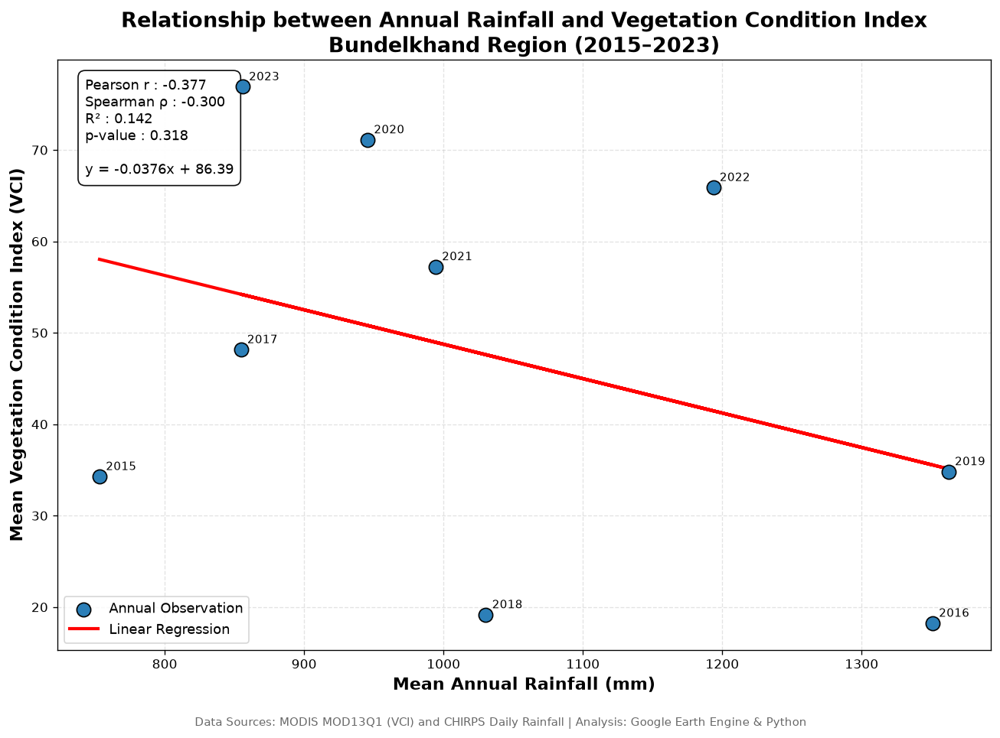


Correlation Plot Saved Successfully.


In [53]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 12 : Publication Correlation Plot (VCI vs Rainfall)
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("GENERATING PUBLICATION QUALITY CORRELATION PLOT")
print("=" * 90)

from sklearn.linear_model import LinearRegression

# ---------------------------------------------------------------
# Variables
# ---------------------------------------------------------------

x = validation_df["Mean_Rainfall_mm"].values.reshape(-1,1)

y = validation_df["Mean_VCI"].values

years_plot = validation_df["Year"].astype(str)

# ---------------------------------------------------------------
# Linear Regression
# ---------------------------------------------------------------

model = LinearRegression()

model.fit(x, y)

y_pred = model.predict(x)

r2 = model.score(x, y)

# ---------------------------------------------------------------
# Figure
# ---------------------------------------------------------------

plt.figure(figsize=(11,8))

# ---------------------------------------------------------------
# Scatter Plot
# ---------------------------------------------------------------

plt.scatter(

    x,

    y,

    s=120,

    color="#2C7FB8",

    edgecolor="black",

    linewidth=1,

    zorder=5,

    label="Annual Observation"

)

# ---------------------------------------------------------------
# Regression Line
# ---------------------------------------------------------------

plt.plot(

    x,

    y_pred,

    color="red",

    linewidth=2.5,

    label="Linear Regression"

)

# ---------------------------------------------------------------
# Year Labels
# ---------------------------------------------------------------

for i, txt in enumerate(years_plot):

    plt.annotate(

        txt,

        (

            x[i][0],

            y[i]

        ),

        xytext=(5,5),

        textcoords="offset points",

        fontsize=9

    )

# ---------------------------------------------------------------
# Grid
# ---------------------------------------------------------------

plt.grid(

    linestyle="--",

    alpha=0.35

)

# ---------------------------------------------------------------
# Labels
# ---------------------------------------------------------------

plt.xlabel(

    "Mean Annual Rainfall (mm)",

    fontsize=13,

    fontweight="bold"

)

plt.ylabel(

    "Mean Vegetation Condition Index (VCI)",

    fontsize=13,

    fontweight="bold"

)

plt.title(

    "Relationship between Annual Rainfall and Vegetation Condition Index\n"
    "Bundelkhand Region (2015–2023)",

    fontsize=16,

    fontweight="bold"

)

# ---------------------------------------------------------------
# Statistics Box
# ---------------------------------------------------------------

equation = (

    f"y = {model.coef_[0]:.4f}x + {model.intercept_:.2f}"

)

stats_text = (

    f"Pearson r : {pearson_r:.3f}\n"

    f"Spearman ρ : {spearman_rho:.3f}\n"

    f"R² : {r2:.3f}\n"

    f"p-value : {pearson_p:.3f}\n\n"

    f"{equation}"

)

plt.text(

    0.03,

    0.97,

    stats_text,

    transform=plt.gca().transAxes,

    fontsize=11,

    verticalalignment="top",

    bbox=dict(

        facecolor="white",

        edgecolor="black",

        alpha=0.95,

        boxstyle="round,pad=0.5"

    )

)

# ---------------------------------------------------------------
# Legend
# ---------------------------------------------------------------

plt.legend(

    fontsize=11,

    loc="lower left"

)

# ---------------------------------------------------------------
# Footer
# ---------------------------------------------------------------

plt.figtext(

    0.5,

    0.005,

    "Data Sources: MODIS MOD13Q1 (VCI) and CHIRPS Daily Rainfall | "
    "Analysis: Google Earth Engine & Python",

    ha="center",

    fontsize=9,

    color="dimgray"

)

# ---------------------------------------------------------------
# Save Figure
# ---------------------------------------------------------------

save_figure(

    filename="VCI_vs_CHIRPS_Correlation.png",

    folder=GRAPH_DIR,

    dpi=300

)

plt.tight_layout(rect=[0,0.03,1,1])

plt.show()

print("\nCorrelation Plot Saved Successfully.")

print("="*90)

GENERATING MULTI-TEMPORAL TREND ANALYSIS
CSV Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Tables/Trend_Analysis_Data.csv
Figure Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Graphs/Trend_Analysis_Dashboard.png


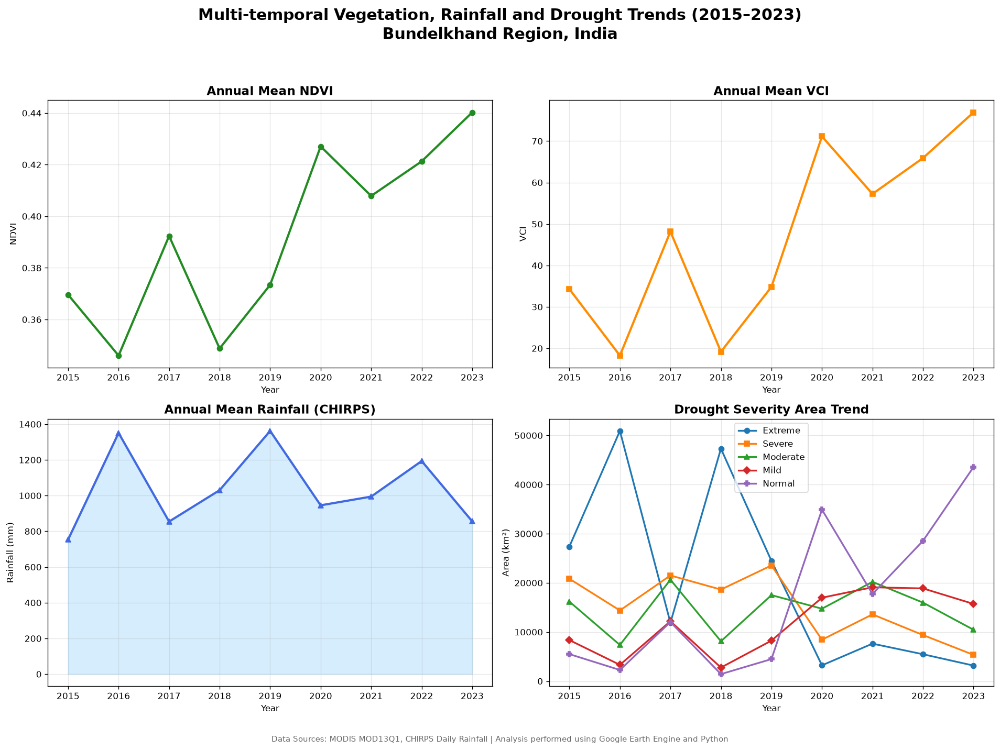


Dashboard Saved Successfully.


In [54]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 13 : Multi-temporal Trend Analysis Dashboard
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("GENERATING MULTI-TEMPORAL TREND ANALYSIS")
print("=" * 90)

# ---------------------------------------------------------------
# Prepare Data
# ---------------------------------------------------------------

trend_df = pd.DataFrame({

    "Year": years,

    "Mean_NDVI": ndvi_stats["Mean_NDVI"],

    "Mean_VCI": vci_statistics["Mean_VCI"],

    "Rainfall_mm": rainfall_stats["Mean_Rainfall_mm"],

    "Extreme_km2": area_statistics["Extreme_km2"],

    "Severe_km2": area_statistics["Severe_km2"],

    "Moderate_km2": area_statistics["Moderate_km2"],

    "Mild_km2": area_statistics["Mild_km2"],

    "Normal_km2": area_statistics["Normal_km2"]

})

save_csv(

    trend_df,

    "Trend_Analysis_Data.csv"

)

# ---------------------------------------------------------------
# Figure
# ---------------------------------------------------------------

fig, axes = plt.subplots(

    2,

    2,

    figsize=(16,12)

)

# ===============================================================
# NDVI Trend
# ===============================================================

axes[0,0].plot(

    trend_df["Year"],

    trend_df["Mean_NDVI"],

    marker="o",

    linewidth=2.5,

    color="forestgreen"

)

axes[0,0].set_title(

    "Annual Mean NDVI",

    fontsize=14,

    fontweight="bold"

)

axes[0,0].set_xlabel("Year")

axes[0,0].set_ylabel("NDVI")

axes[0,0].grid(alpha=0.3)

# ===============================================================
# VCI Trend
# ===============================================================

axes[0,1].plot(

    trend_df["Year"],

    trend_df["Mean_VCI"],

    marker="s",

    linewidth=2.5,

    color="darkorange"

)

axes[0,1].set_title(

    "Annual Mean VCI",

    fontsize=14,

    fontweight="bold"

)

axes[0,1].set_xlabel("Year")

axes[0,1].set_ylabel("VCI")

axes[0,1].grid(alpha=0.3)

# ===============================================================
# Rainfall Trend
# ===============================================================

axes[1,0].plot(

    trend_df["Year"],

    trend_df["Rainfall_mm"],

    marker="^",

    linewidth=2.5,

    color="royalblue"

)

axes[1,0].fill_between(

    trend_df["Year"],

    trend_df["Rainfall_mm"],

    color="lightskyblue",

    alpha=0.35

)

axes[1,0].set_title(

    "Annual Mean Rainfall (CHIRPS)",

    fontsize=14,

    fontweight="bold"

)

axes[1,0].set_xlabel("Year")

axes[1,0].set_ylabel("Rainfall (mm)")

axes[1,0].grid(alpha=0.3)

# ===============================================================
# Drought Area Trend
# ===============================================================

axes[1,1].plot(

    trend_df["Year"],

    trend_df["Extreme_km2"],

    marker="o",

    linewidth=2,

    label="Extreme"

)

axes[1,1].plot(

    trend_df["Year"],

    trend_df["Severe_km2"],

    marker="s",

    linewidth=2,

    label="Severe"

)

axes[1,1].plot(

    trend_df["Year"],

    trend_df["Moderate_km2"],

    marker="^",

    linewidth=2,

    label="Moderate"

)

axes[1,1].plot(

    trend_df["Year"],

    trend_df["Mild_km2"],

    marker="D",

    linewidth=2,

    label="Mild"

)

axes[1,1].plot(

    trend_df["Year"],

    trend_df["Normal_km2"],

    marker="P",

    linewidth=2,

    label="Normal"

)

axes[1,1].set_title(

    "Drought Severity Area Trend",

    fontsize=14,

    fontweight="bold"

)

axes[1,1].set_xlabel("Year")

axes[1,1].set_ylabel("Area (km²)")

axes[1,1].legend()

axes[1,1].grid(alpha=0.3)

# ===============================================================
# Dashboard Title
# ===============================================================

fig.suptitle(

    "Multi-temporal Vegetation, Rainfall and Drought Trends (2015–2023)\n"
    "Bundelkhand Region, India",

    fontsize=18,

    fontweight="bold"

)

# ---------------------------------------------------------------
# Footer
# ---------------------------------------------------------------

plt.figtext(

    0.5,

    0.005,

    "Data Sources: MODIS MOD13Q1, CHIRPS Daily Rainfall | "
    "Analysis performed using Google Earth Engine and Python",

    ha="center",

    fontsize=9,

    color="dimgray"

)

# ---------------------------------------------------------------
# Save Figure
# ---------------------------------------------------------------

save_figure(

    filename="Trend_Analysis_Dashboard.png",

    folder=GRAPH_DIR,

    dpi=300

)

plt.tight_layout(rect=[0,0.03,1,0.95])

plt.show()

print("\nDashboard Saved Successfully.")

print("=" * 90)

In [55]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 14 : Export Final Results
# Author : Anshuman Tripathi
# ===============================================================

print("=" * 90)
print("EXPORTING FINAL PROJECT RESULTS")
print("=" * 90)

from datetime import datetime

# ---------------------------------------------------------------
# Output File
# ---------------------------------------------------------------

excel_file = OUTPUT_DIR / "Tables" / "Drought_Assessment_Final_Report.xlsx"

# ---------------------------------------------------------------
# Export All Tables
# ---------------------------------------------------------------

with pd.ExcelWriter(excel_file, engine="openpyxl") as writer:

    # NDVI Statistics
    ndvi_stats.to_excel(
        writer,
        sheet_name="NDVI_Statistics",
        index=False
    )

    # VCI Statistics
    vci_statistics.to_excel(
        writer,
        sheet_name="VCI_Statistics",
        index=False
    )

    # Drought Area Statistics
    area_statistics.to_excel(
        writer,
        sheet_name="Drought_Area",
        index=False
    )

    # Rainfall Statistics
    rainfall_stats.to_excel(
        writer,
        sheet_name="Rainfall_Statistics",
        index=False
    )

    # Correlation Dataset
    validation_df.to_excel(
        writer,
        sheet_name="Validation_Data",
        index=False
    )

    # Correlation Report
    correlation_report.to_excel(
        writer,
        sheet_name="Correlation",
        index=False
    )

    # Polygon Statistics
    polygon_statistics.to_excel(
        writer,
        sheet_name="Polygon_Area",
        index=False
    )

    # Trend Data
    trend_df.to_excel(
        writer,
        sheet_name="Trend_Data",
        index=False
    )

print("Excel Workbook Created")

# ---------------------------------------------------------------
# Research Summary
# ---------------------------------------------------------------

summary = pd.DataFrame({

    "Parameter":[

        "Project",

        "Study Area",

        "Satellite Dataset",

        "Rainfall Dataset",

        "Study Period",

        "Spatial Resolution",

        "Number of Years",

        "Pearson Correlation",

        "Spearman Correlation",

        "R Squared",

        "P Value",

        "Generated",

        "Author"

    ],

    "Value":[

        "Multi-temporal Drought Assessment using Vegetation Condition Index (VCI)",

        "Bundelkhand Region, India",

        "MODIS MOD13Q1 Version 6.1",

        "CHIRPS Daily",

        "2015-2023",

        "250 m",

        len(years),

        round(pearson_r,4),

        round(spearman_rho,4),

        round(r_squared,4),

        round(pearson_p,6),

        datetime.now().strftime("%d-%m-%Y %H:%M"),

        "Anshuman Tripathi"

    ]

})

save_csv(

    summary,

    "Research_Project_Summary.csv"

)

print("Research Summary Saved")

# ---------------------------------------------------------------
# Generated Figures
# ---------------------------------------------------------------

figures = sorted(GRAPH_DIR.glob("*.png"))

print("\nGenerated Figures")

for fig in figures:

    print("✓", fig.name)

# ---------------------------------------------------------------
# Generated Tables
# ---------------------------------------------------------------

tables = sorted((OUTPUT_DIR / "Tables").glob("*"))

print("\nGenerated Tables")

for table in tables:

    print("✓", table.name)

# ---------------------------------------------------------------
# Final Statistics
# ---------------------------------------------------------------

print("\n")

print("=" * 90)

print("PROJECT SUMMARY")

print("=" * 90)

print(f"Study Area           : Bundelkhand Region")

print(f"Study Period         : 2015–2023")

print(f"Years Analysed       : {len(years)}")

print(f"NDVI Images          : {len(years)}")

print(f"Rainfall Images      : {len(years)}")

print(f"Pearson r            : {pearson_r:.4f}")

print(f"Spearman rho         : {spearman_rho:.4f}")

print(f"Coefficient (R²)     : {r_squared:.4f}")

print(f"P-value              : {pearson_p:.6f}")

print("=" * 90)

print("Excel Report :", excel_file)

print("=" * 90)

print("ALL RESULTS EXPORTED SUCCESSFULLY")

print("=" * 90)

EXPORTING FINAL PROJECT RESULTS
Excel Workbook Created
CSV Saved : /home/minato/project/main project/Drought-Severity-Mapping-using-Vegetation-Condition-Index-VCI-main/results/Tables/Research_Project_Summary.csv
Research Summary Saved

Generated Figures
✓ Trend_Analysis_Dashboard.png
✓ VCI_vs_CHIRPS_Correlation.png

Generated Tables
✓ CHIRPS_Raster_Validation_Report.csv
✓ Drought_Area_Statistics.csv
✓ Drought_Assessment_Final_Report.xlsx
✓ Drought_Class_Pixel_Count.csv
✓ NDVI_Raster_Validation_Report.csv
✓ Polygon_Area_Statistics.csv
✓ Research_Project_Summary.csv
✓ Trend_Analysis_Data.csv
✓ VCI_CHIRPS_Correlation_Report.csv
✓ VCI_CHIRPS_Validation.csv
✓ VCI_Statistics.csv


PROJECT SUMMARY
Study Area           : Bundelkhand Region
Study Period         : 2015–2023
Years Analysed       : 9
NDVI Images          : 9
Rainfall Images      : 9
Pearson r            : -0.3766
Spearman rho         : -0.3000
Coefficient (R²)     : 0.1418
P-value              : 0.317779
Excel Report : /home/minat

In [56]:
# ===============================================================
# Multi-temporal Drought Assessment using MODIS NDVI & VCI
# Cell 15 : Project Completion Report
# Author : Anshuman Tripathi
# ===============================================================

from datetime import datetime
import platform
import sys

print("=" * 100)
print("                 MULTI-TEMPORAL DROUGHT ASSESSMENT PROJECT")
print("=" * 100)

print("\nPROJECT INFORMATION\n")

print(f"Project Title      : Multi-temporal Drought Assessment using Vegetation Condition Index (VCI)")
print(f"Study Area         : Bundelkhand Region, India")
print(f"Study Period       : 2015–2023")
print(f"Satellite Dataset  : MODIS MOD13Q1 Version 6.1")
print(f"Rainfall Dataset   : CHIRPS Daily")
print(f"Spatial Resolution : 250 m")
print(f"Programming        : Google Earth Engine + Python")
print(f"Author             : Anshuman Tripathi")

print("\n")

print("=" * 100)
print("PROJECT WORKFLOW")
print("=" * 100)

workflow = [

    "✓ Bundelkhand AOI Preparation",

    "✓ MODIS NDVI Processing",

    "✓ Annual NDVI Composite Generation",

    "✓ NDVI Min / NDVI Max Computation",

    "✓ Vegetation Condition Index (VCI)",

    "✓ Drought Severity Classification",

    "✓ Publication Quality Maps",

    "✓ Raster to Vector Conversion",

    "✓ Polygon Area Statistics",

    "✓ CHIRPS Rainfall Processing",

    "✓ Rainfall Validation",

    "✓ VCI vs Rainfall Correlation",

    "✓ Trend Analysis",

    "✓ Final Report Export"

]

for step in workflow:

    print(step)

print("\n")

print("=" * 100)
print("KEY RESULTS")
print("=" * 100)

print(f"Years Analysed                 : {len(years)}")

print(f"Pearson Correlation (r)        : {pearson_r:.4f}")

print(f"Spearman Correlation (ρ)       : {spearman_rho:.4f}")

print(f"Coefficient of Determination   : {r_squared:.4f}")

print(f"P-value                        : {pearson_p:.6f}")

if pearson_p < 0.05:

    significance = "Statistically Significant"

else:

    significance = "Not Statistically Significant"

print(f"Statistical Interpretation     : {significance}")

print("\n")

print("=" * 100)
print("GENERATED OUTPUTS")
print("=" * 100)

folders = [

    "Maps",

    "Graphs",

    "Raster",

    "Vector",

    "Tables"

]

for folder in folders:

    path = OUTPUT_DIR / folder

    if path.exists():

        files = list(path.glob("*"))

        print(f"{folder:<10} : {len(files)} files")

print("\n")

print("=" * 100)
print("SYSTEM INFORMATION")
print("=" * 100)

print(f"Python Version : {sys.version.split()[0]}")

print(f"Operating System : {platform.system()}")

print(f"Execution Time : {datetime.now().strftime('%d-%m-%Y %H:%M:%S')}")

print("\n")

print("=" * 100)
print("SCIENTIFIC CONCLUSION")
print("=" * 100)

print("""

The Vegetation Condition Index (VCI) derived from MODIS NDVI imagery
was successfully used to monitor drought conditions across the
Bundelkhand region from 2015 to 2023.

Annual drought severity maps, vector layers, and area statistics
were generated for each year.

Cross-validation with CHIRPS rainfall indicated a weak negative
relationship between annual rainfall and vegetation condition
(Pearson r = {:.3f}, R² = {:.3f}), suggesting that vegetation
response is influenced by additional environmental factors such as
soil moisture, irrigation practices, land use, and seasonal rainfall
distribution.

The developed workflow demonstrates an operational framework for
multi-temporal drought assessment using remote sensing and
geospatial analysis.

""".format(pearson_r, r_squared))

print("=" * 100)

print("PROJECT STATUS : COMPLETED SUCCESSFULLY")

print("=" * 100)

print("\nAll outputs have been exported to:\n")

print(OUTPUT_DIR)

print("\n")

print("=" * 100)
print("THANK YOU")
print("=" * 100)

                 MULTI-TEMPORAL DROUGHT ASSESSMENT PROJECT

PROJECT INFORMATION

Project Title      : Multi-temporal Drought Assessment using Vegetation Condition Index (VCI)
Study Area         : Bundelkhand Region, India
Study Period       : 2015–2023
Satellite Dataset  : MODIS MOD13Q1 Version 6.1
Rainfall Dataset   : CHIRPS Daily
Spatial Resolution : 250 m
Programming        : Google Earth Engine + Python
Author             : Anshuman Tripathi


PROJECT WORKFLOW
✓ Bundelkhand AOI Preparation
✓ MODIS NDVI Processing
✓ Annual NDVI Composite Generation
✓ NDVI Min / NDVI Max Computation
✓ Vegetation Condition Index (VCI)
✓ Drought Severity Classification
✓ Publication Quality Maps
✓ Raster to Vector Conversion
✓ Polygon Area Statistics
✓ CHIRPS Rainfall Processing
✓ Rainfall Validation
✓ VCI vs Rainfall Correlation
✓ Trend Analysis
✓ Final Report Export


KEY RESULTS
Years Analysed                 : 9
Pearson Correlation (r)        : -0.3766
Spearman Correlation (ρ)       : -0.3000
Coeff